# Assignment 4: Water Balance for DTU Campus

*Notebook made by: Markus Jehl (s243647), Maja Søholm Eskelund (s235129), Malthe Tretow-Loof (s242273) & Sarah Badstue Ringgaard Sørensen (s244739)*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sympy import *
import scipy as sp
import rasterio as rio
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import matplotlib.dates as mdates
import matplotlib.ticker as mticker

## Step 1 - Catchment characterization

In [2]:
with rio.open(r'../Background/Data/CatchmentCharacterization/Land_Cover_Kongens_Lyngby.tif') as src: landuse = src.read(1)
with rio.open(r'../Background/Data/CatchmentCharacterization/catchment_0.tif') as src: catchment00 = src.read(1)
transform = src.transform
with rio.open(r'../Background/Data/CatchmentCharacterization/catchment_1.tif') as src: catchment01 = src.read(1)
with rio.open(r'../Background/Data/CatchmentCharacterization/catchment_2.tif') as src: catchment02 = src.read(1)
with rio.open(r'../Background/Data/CatchmentCharacterization/Terrain_Buildings_Rain_Kongens_Lyngby.tif') as src: terrain = src.read(1)

### Q 1) Create a plot showing an overview of the different types of landuse in the catchment. 

The tif file "Land_Cover_Kongens_Lyngby.tif" defined as "landuse", contains information on the different landuse types at DTU campus. 
The list, unique_ids is created, to obtain knowledge of which landuse types are present at DTU. 

In [3]:
unique_ids = np.unique(landuse)
print(unique_ids)

[ 1  3  6  7  9 10 15 16]


In [4]:
# Define landcover_id dictionary, containing name and color for each id in landuse data
landcover_id = {
    1: {'name':'Bare land',         'color':'tan'},
    3: {'name':'Other paved',       'color':'grey'},
    6: {'name':'Shallow vegetation','color':'lightgreen'},
    7: {'name':'Dense vegetation',  'color':'darkgreen'},
    9: {'name':'Paved road',        'color':'black'},
    10:{'name':'Unpaved road',      'color':'saddlebrown'},
    15:{'name':'Bare rock',         'color':'steelblue'},
    16:{'name':'Building',          'color':'red'}
}

# Define catchment dictionary containing data and color
catchments= {
    'catchment00':{'name': 'catchment00','data': catchment00,'color':'limegreen' },
    'catchment01':{'name': 'catchment01','data': catchment01,'color': 'orange'},
    'catchment02':{'name': 'catchment02','data': catchment02,'color': 'blue'}
}

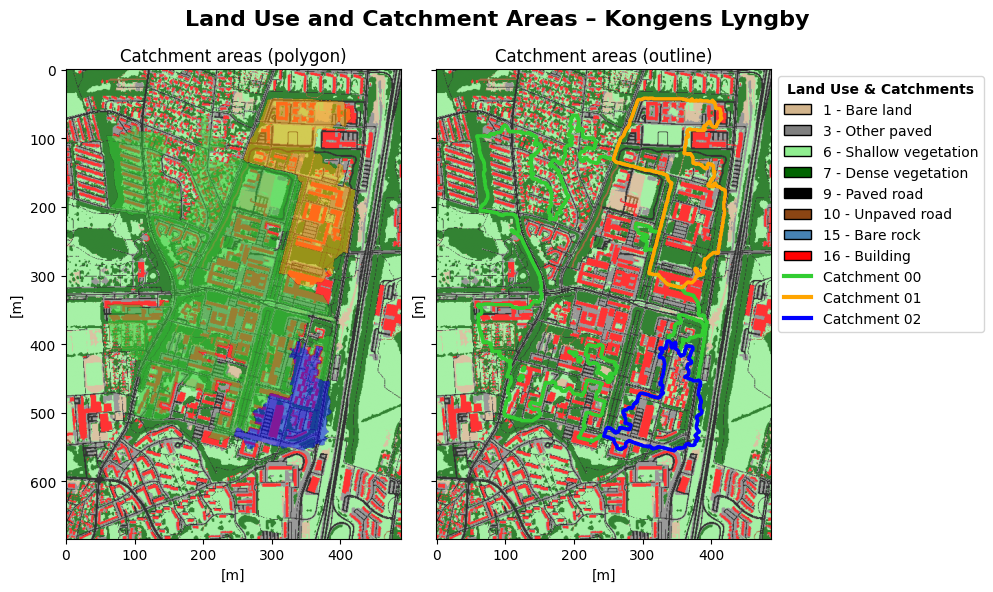

In [5]:
# Initialise figure and axis
fig, ax = plt.subplots(
    1, 2, figsize=(10, 6),
    sharex=True, sharey=True)

# Define Land use colormap
colors = [landcover_id[id]['color'] for id in unique_ids]
cmap = ListedColormap(colors)
norm = BoundaryNorm(list(unique_ids) + [unique_ids[-1] + 1], len(unique_ids))

# Create subplots
ax[0].imshow(landuse, cmap=cmap, norm=norm, alpha=0.8)
ax[1].imshow(landuse, cmap=cmap, norm=norm, alpha=0.8)

for c_name, c_dict in catchments.items():
    # Define mask for area
    masked = np.ma.masked_where(c_dict['data'] == 0, c_dict['data'])
    ax[0].imshow(
        masked,
        cmap=ListedColormap([c_dict['color']]),
        alpha=0.5)

    ax[1].contour(
        c_dict['data'],
        levels=[0.5],
        colors=c_dict['color'],
        linewidths=2.5)

ax[0].set_title("Catchment areas (polygon)")
ax[1].set_title("Catchment areas (outline)")

# Akse-labels (meter) + aspect
for a in ax:
    a.set_xlabel("[m]")
    a.set_ylabel("[m]")
    a.set_aspect("equal")
    a.ticklabel_format(style="plain")

# Legend: Land Use + Catchments 
legend_elements = []

# Land use
for id in unique_ids:
    legend_elements.append(
        Patch(
            facecolor=landcover_id[id]['color'],
            edgecolor="black",
            label=f"{id} - {landcover_id[id]['name']}"))

# Catchments
for c_name, c_dict in catchments.items():
    legend_elements.append(
        Line2D(
            [0], [0],
            color=c_dict['color'],
            linewidth=3,
            label=c_name.replace("catchment", "Catchment ")))

ax[1].legend(
    handles=legend_elements,
    loc="upper left",
    bbox_to_anchor=(1, 1),
    title="Land Use & Catchments",
    title_fontproperties={"weight": "bold"})

# Figur-titel
fig.suptitle(
    "Land Use and Catchment Areas – Kongens Lyngby",
    fontsize=16,
    fontweight="bold")

plt.tight_layout()
plt.show()

The figure shows the spatial distribution of land use types across the campus together with the three delineated catchment areas. It illustrates how different surfaces are distributed within each catchment and how the areas are separated in relation to the surrounding layout.

### Q 2) Table summarizing the total area of each land use class in each catchment. Which landuse classes do you think are relevant to consider for the water balance calculations?

It is relevant to consider the following landuses in the water balance calculations: 
- Bare land
- Shallow vegetation
- Dense vegetation 
- Unpaved road 

Because it is natural landuses in which, water can ooze down. The water cannot penetrate the material of paved road, rocks and buildings.


In [6]:
# Area per pixel (ha)
ha_per_pixel = (src.res[0] * src.res[1]) / 10000


# Basis DataFrame: land use classes
df_landtype = pd.DataFrame({'Land Cover Type': [landcover_id[id]['name'] for id in landcover_id]})


# Calculate area per landuse type per catchment
for c_name, c_dict in catchments.items():

    # Mask landuse til catchment
    landuse_masked = np.where(c_dict['data'] > 0, landuse, -1)

    areas_ha = []
    for id in landcover_id:
        pixel_count = np.sum(landuse_masked == id)
        areas_ha.append(pixel_count * ha_per_pixel)

    df_landtype[f'{c_name} (ha)'] = areas_ha


# Calculate total area per catchment 
total_row = {'Land Cover Type': 'Total area in catchment'}

for c_name, c_dict in catchments.items():
    active_pixels = np.sum(c_dict['data'] > 0)
    total_area_ha = active_pixels * ha_per_pixel
    total_row[f'{c_name} (ha)'] = total_area_ha


# Combine the toal are with the dataframe
df_landtype = pd.concat([df_landtype, pd.DataFrame([total_row])], ignore_index=True)

df_landtype['Total (ha)']=df_landtype.iloc[:, 1:].sum(axis=1)

df_landtype.style.set_properties(
    subset=pd.IndexSlice[df_landtype.index[-1], :],
    **{'font-weight': 'bold', 'font-style': 'italic'}).format("{:.2f}", subset=df_landtype.columns[1:])

,Land Cover Type,catchment00 (ha),catchment01 (ha),catchment02 (ha),Total (ha)
0,Bare land,2.51,0.66,0.27,3.44
1,Other paved,19.41,5.39,2.98,27.78
2,Shallow vegetation,10.03,3.42,1.49,14.94
3,Dense vegetation,24.84,7.19,2.48,34.51
4,Paved road,11.34,3.76,1.73,16.83
5,Unpaved road,0.89,0.06,0.00,0.95
6,Bare rock,0.00,0.00,0.00,0.00
7,Building,18.50,4.74,2.49,25.73
8,Total area in catchment,87.51,25.21,11.44,124.16


## Step 2 - Radiation balance and reference evapotranspiration

### Q 3.a) Write down the equation for net radiation and formulate how you will compute each component based on the avilable data.

The net radiation is computed as the sum of net shortwave radiation and net longwave radiation:

$$R_n = S_n + L_n = S_{in} - S_{out} + L_{in} - L_{out}$$

The net shortwave radiation can be expressed by $S_n = S_t (1 - \alpha)$. Where $S_t$ is the net (shortwave) solar radiation at groundlevel Since the DTU weather station provides measurements of global horizontal irradiance (GHI), this is used as the incoming shortwave radiation $S_{in}$. The reflected radiation can be determined by the albedo, in this case we will be using the albedo for grass surface at $\alpha = 0.23$. The net shortwave radiation can therefore be found as $$ S_n = GHI (1 - 0.25)$$

The net longwave radiation can be expressed by $L_n = L_{in}-L_{out}$. 
- The incomming radiation $L_{in}$ is given directly in the dataset as Longwave Downwelling Irradiance (LWD). 
- The outgoing longwave radiation $L_{out}$ is estimated using the Stefan Boltzmann law:

$$L_{out} = \varepsilon \sigma T^4$$

where 
- $\varepsilon$ is the emissivity of the surface. For vegetated surface, $\varepsilon = 0.98$ is typically assumed. 
- Sigma is the Stefan Boltsman constant, $\sigma = 5.67 \cdot 10^{-8} \,W m^{-2} K^{-4}$ is used. 
- $T$ is the air temperature, which is given in the dataset in Celsius, and can easily be converted to Kelvin by adding 273.15. 

The net longwave radiation can therefore be found as $$ L_n = LWD - 5.67 \cdot 10^{-8} \cdot 0.98 \cdot (T_{air}+273.15)^4$$

Combining the expressions, the final equation for net radiation is:

$$R_n = GHI \cdot (1 - 0.25) + LWD - 5.67 \cdot 10^{-8}\cdot 0.98 \cdot (T_{air}+273.15)^4$$

### Q 3.b) 

In [7]:
"""
Import of meterological data 
"""
met_data = pd.read_csv('../Background/Data/MeteorologicalData/meteorological_data.csv', sep=';')

met_data.rename(columns={'Time(utc)': 'time'}, inplace=True) # rename timestamp column
met_data['time'] = pd.to_datetime(met_data['time']) # convert to datetime
met_data = met_data.set_index('time')

# Define constants
sigma = 5.67e-8
epsilon = 0.98
albedo = 0.23

# Temperature in Kelvin
T_kelvin = met_data['air_temperature'] + 273.15

# Net shortwave radiation
met_data['R_ns'] = met_data['GHI'] * (1 - albedo)

# Net longwave radiation
met_data['R_nl'] = met_data['LWD'] - epsilon * sigma * (T_kelvin**4)

# Net radiation
met_data['R_n'] = met_data['R_ns'] + met_data['R_nl']


The calculated radiation time series show a clear seasonal pattern that visually corresponds with the DMI technical report. In the daily aggregation plot, the net shortwave radiation follows the bell-shaped curve of the global radiation seen in the DMI data, reaching an annual peak in summer and an annual minimum in winter. The net longwave radiation remains negative throughout the year, causing the total net radiation to dip slightly below zero during the winter months.

The hourly aggregation plot further validates the results, as the shortwave peaks of 700-800 $W/m^2$ match the levels recorded at DMI’s stations. This resolution effectively captures the rapid variations in radiation levels that are also visible in the DMI reference data. The overall patterns are consistent with the provided meteorological observations.

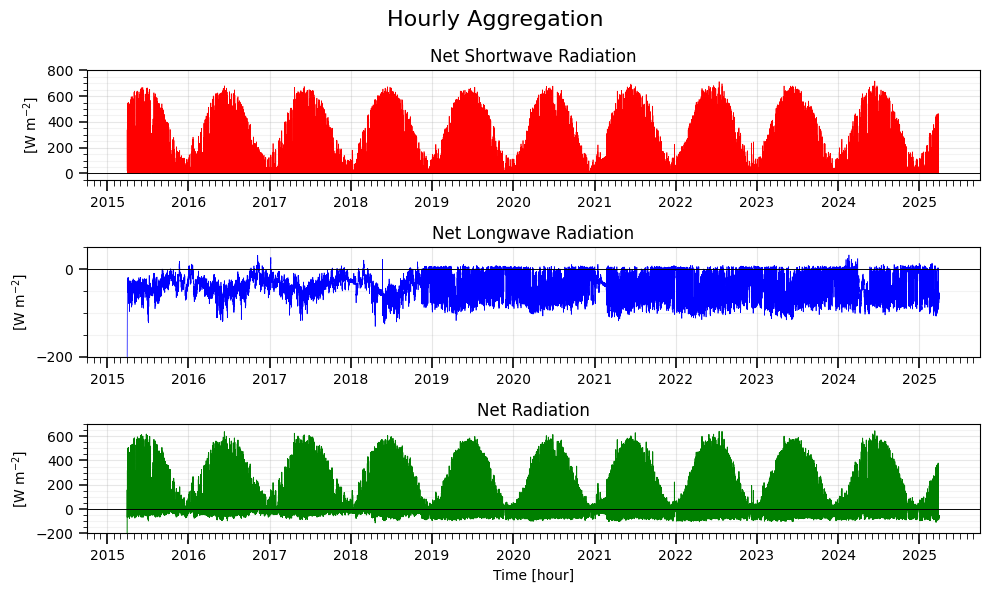

In [8]:
hourly_data = met_data.resample('h').mean()

fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=False)

fig.suptitle('Hourly Aggregation', fontsize=16)

# Net Shortwave
axes[0].plot(hourly_data.index, hourly_data['R_ns'],
             color='red', linewidth=0.5)
axes[0].axhline(0, color='k', linewidth=0.5)
axes[0].set_ylabel('[W m$^{-2}$]')
axes[0].set_ylim(-50, 800)
axes[0].set_title('Net Shortwave Radiation')
axes[0].grid(True, alpha=0.3)

# Net Longwave
axes[1].plot(hourly_data.index, hourly_data['R_nl'],
             color='blue', linewidth=0.5)
axes[1].axhline(0, color='k', linewidth=0.5)
axes[1].set_ylabel('[W m$^{-2}$]')
axes[1].set_ylim(-200, 50)
axes[1].set_title('Net Longwave Radiation')
axes[1].grid(True, alpha=0.3)

# Net Radiation
axes[2].plot(hourly_data.index, hourly_data['R_n'],
             color='green', linewidth=0.7)
axes[2].axhline(0, color='k', linewidth=0.5)
axes[2].set_ylabel('[W m$^{-2}$]')
axes[2].set_ylim(-200, 700)
axes[2].set_title('Net Radiation')
axes[2].set_xlabel('Time [hour]')
axes[2].grid(True, alpha=0.3)



for ax in axes:
    ax.axhline(0, color='k', linewidth=0.4)
    ax.grid(True, which='major', axis='y', alpha=0.3)

    # Major og minor y-ticks
    ax.yaxis.set_major_locator(mticker.MultipleLocator(200))
    ax.yaxis.set_minor_locator(mticker.MultipleLocator(50))

    ax.tick_params(axis='y', which='major',
                   length=6, width=1.1)
    ax.tick_params(axis='y', which='minor',
                   length=3, width=0.6)

    # Grid (kun y for overskuelighed)
    ax.grid(True, which='major', axis='y', alpha=0.3)
    ax.grid(True, which='minor', axis='y', alpha=0.15)

    # Nul-linje
    ax.axhline(0, color='k', linewidth=0.4)

    # --- X-akse ticks ---
    # Tynde ticks: hver måned
    ax.xaxis.set_minor_locator(mdates.MonthLocator())

    # Tykke ticks: hvert år
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

    # Tick styling
    ax.tick_params(axis='x', which='major',
                   length=8, width=1.2)
    ax.tick_params(axis='x', which='minor',
                   length=4, width=0.6)

plt.tight_layout()
plt.show()

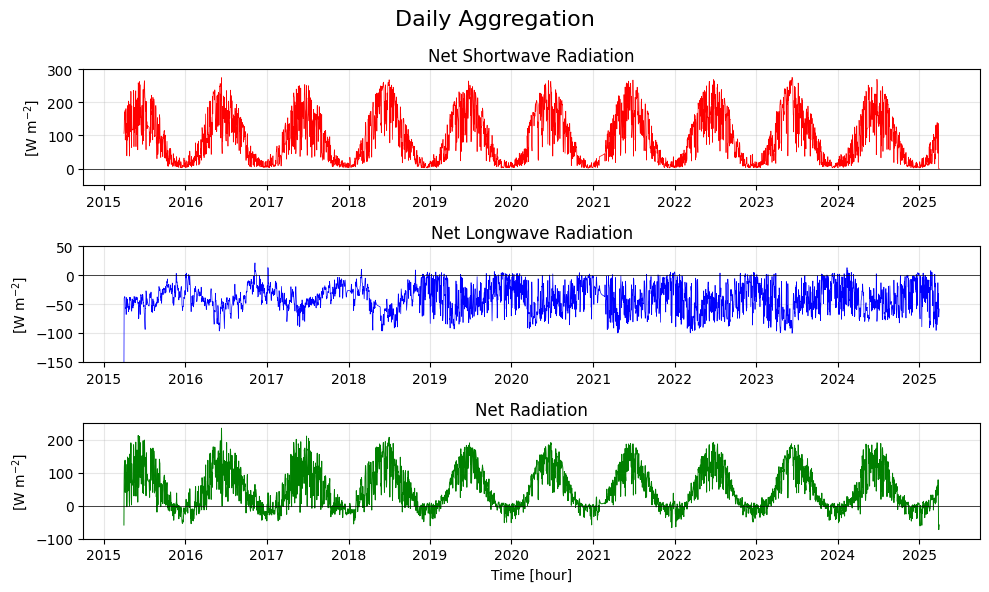

In [9]:
met_daily_data = met_data.resample('D').mean()

fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=False)

fig.suptitle('Daily Aggregation', fontsize=16)

# Net Shortwave
axes[0].plot(met_daily_data.index, met_daily_data['R_ns'],
             color='red', linewidth=0.5)
axes[0].axhline(0, color='k', linewidth=0.5)
axes[0].set_ylabel('[W m$^{-2}$]')
axes[0].set_ylim(-50, 300)
axes[0].set_title('Net Shortwave Radiation')
axes[0].grid(True, alpha=0.3)

# Net Longwave
axes[1].plot(met_daily_data.index, met_daily_data['R_nl'],
             color='blue', linewidth=0.5)
axes[1].axhline(0, color='k', linewidth=0.5)
axes[1].set_ylabel('[W m$^{-2}$]')
axes[1].set_ylim(-150, 50)
axes[1].set_title('Net Longwave Radiation')
axes[1].grid(True, alpha=0.3)

# Net Radiation
axes[2].plot(met_daily_data.index, met_daily_data['R_n'],
             color='green', linewidth=0.7)
axes[2].axhline(0, color='k', linewidth=0.5)
axes[2].set_ylabel('[W m$^{-2}$]')
axes[2].set_ylim(-100, 250)
axes[2].set_title('Net Radiation')
axes[2].set_xlabel('Time [hour]')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

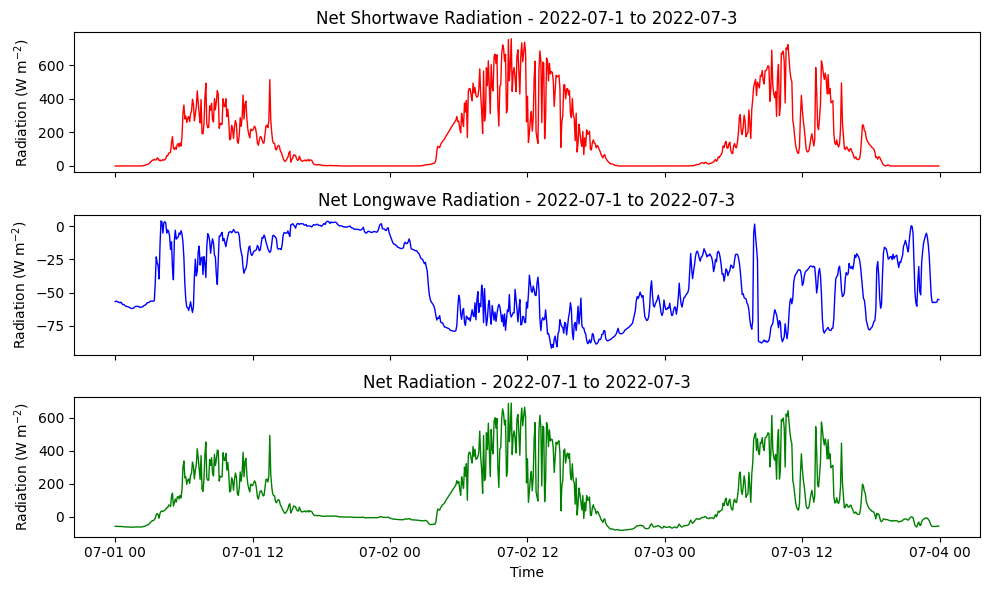

In [10]:
start_date = '2022-07-1'
end_date = '2022-07-3'

zoomed_data = met_data.loc[start_date:end_date]

fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True)

axes[0].plot(zoomed_data.index, zoomed_data['R_ns'], 'red', linewidth=1, label='Net Shortwave (R_ns)')
axes[0].set_ylabel('Radiation (W m$^{-2}$)')
axes[0].set_title(f'Net Shortwave Radiation - {start_date} to {end_date}')

axes[1].plot(zoomed_data.index, zoomed_data['R_nl'], 'blue', linewidth=1, label='Net Longwave (R_nl)')
axes[1].set_ylabel('Radiation (W m$^{-2}$)')
axes[1].set_title(f'Net Longwave Radiation - {start_date} to {end_date}')

axes[2].plot(zoomed_data.index, zoomed_data['R_n'], 'green', linewidth=1, label='Net Radiation (R_n)')
axes[2].set_ylabel('Radiation (W m$^{-2}$)')
axes[2].set_title(f'Net Radiation - {start_date} to {end_date}')
axes[2].set_xlabel('Time')

plt.tight_layout()
plt.show()

The zoomed-in hourly plot illustrates the diurnal cycle between July 1st and July 3rd, 2022. The net shortwave radiation increases after sunrise, reaching its peak around midday before returning to zero at night. During the same period, the net longwave radiation remains predominantly negative. Consequently, the total net radiation follows the shortwave pattern during daylight hours but maintains a negative balance at night due to the continuous net longwave radiation loss.

### Q 3.c Compute ground heat flux for your time series. Create a plot showing net radiation and ground heat flux for four winter and four summer days. Interpret the patterns. 

The shortwave radiation (solar) is stronger in the summertime, than in winter.
The pattern for the summer days, shows higly fluctuating net radiation values, 
being high at the middel of the day. and negative at night.

We observe, that G is possitive during the day and negative during the night. 
When G is possitve energy is transfered from the air to the ground, and vice versa. 
The ground heat flux is similary fluktuating , but not as much as RN.

 

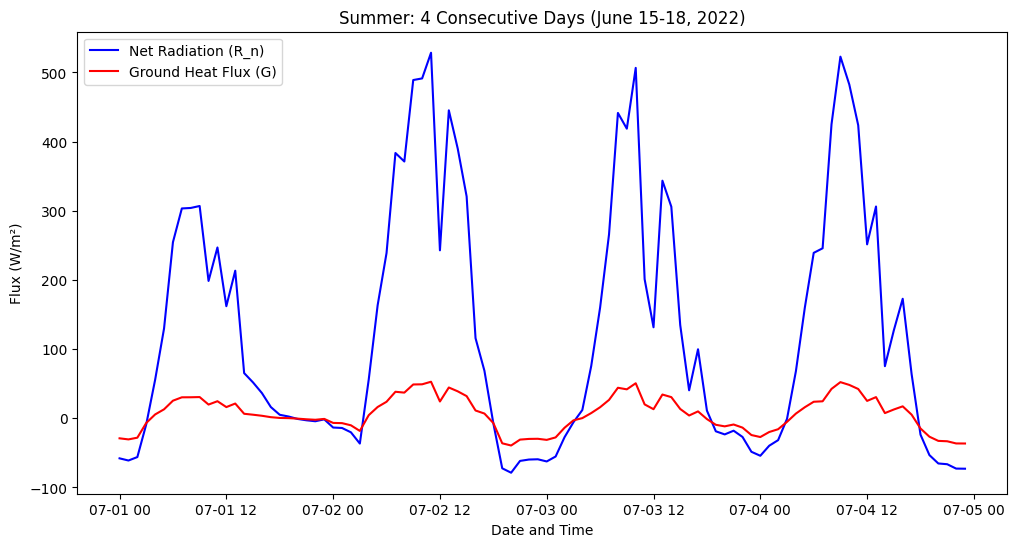

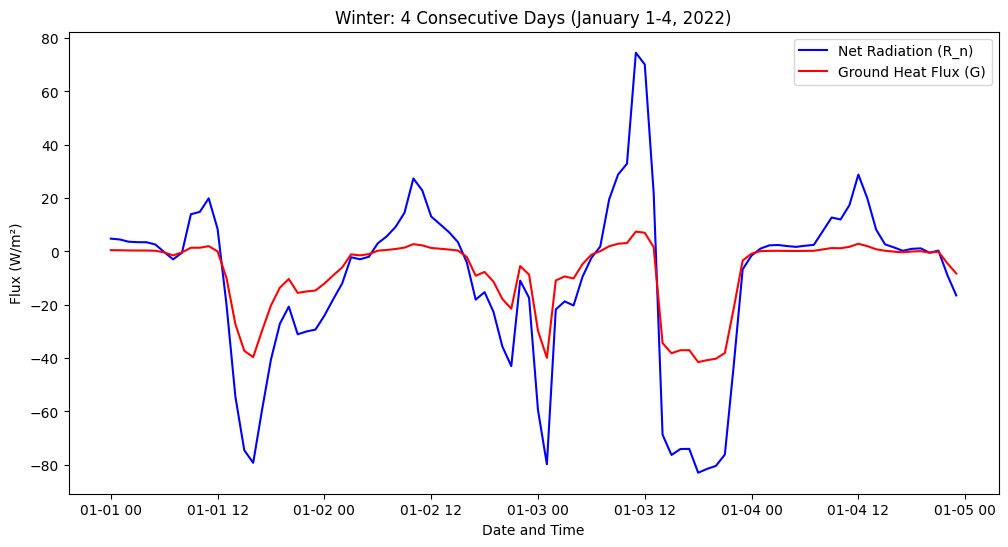

In [11]:
def calculate_ground_heat_flux(R_n):
    """
    FAO-56: G = 0.1 * R_n for daytime, G = 0.5 * R_n for nighttime
    """
    G = R_n.copy()
    G[R_n > 0] = 0.1 * R_n[R_n > 0]  # Daytime
    G[R_n <= 0] = 0.5 * R_n[R_n <= 0]  # Nighttime
    return G

met_data['G'] = calculate_ground_heat_flux(met_data['R_n'])

met_hourly_data = met_data.resample('h').mean()

summer_start = '2022-07-1'
summer_end = '2022-07-4'  

summer_4days = met_hourly_data.loc[summer_start:summer_end]

plt.figure(figsize=(12, 6))
plt.plot(summer_4days.index, summer_4days['R_n'], 'blue', linewidth=1.5, label='Net Radiation (R_n)')
plt.plot(summer_4days.index, summer_4days['G'], 'red', linewidth=1.5, label='Ground Heat Flux (G)')
plt.xlabel('Date and Time')
plt.ylabel('Flux (W/m²)')
plt.title('Summer: 4 Consecutive Days (June 15-18, 2022)')
plt.legend()
plt.show()

winter_start = '2023-01-1'
winter_end = '2023-01-4'

winter_4days = met_hourly_data.loc[winter_start:winter_end]

plt.figure(figsize=(12, 6))
plt.plot(winter_4days.index, winter_4days['R_n'], 'blue', linewidth=1.5, label='Net Radiation (R_n)')
plt.plot(winter_4days.index, winter_4days['G'], 'red', linewidth=1.5, label='Ground Heat Flux (G)')
plt.xlabel('Date and Time')
plt.ylabel('Flux (W/m²)')
plt.title('Winter: 4 Consecutive Days (January 1-4, 2022)')
plt.legend()
plt.show()

The comparison between the summer and winter periods shows a significant shift in the surface energy balance. In the summer plot, the net radiation reaches high positive peaks exceeding 500 $W/m^2$ during midday, which drives a positive ground heat flux as energy is transferred into the soil. At night, net radiation becomes slightly negative, and $G$ follows this pattern by moving toward negative values, marking a limited release of heat from the ground back to the atmosphere.

In the winter plot, the dynamics changes as net radiation is considerably lower, peaking only between 20 and 70 $W/m^2$ during the brief daylight hours. The net radiation remains negative for the majority of the 24-hour cycle, reaching values as low as approximately -80 $W/m^2$, which results in grouund heat flux also remaining predominantly negative. This indicates that during the winter period, the ground consistently releases heat to the atmosphere rather than absorbing it. In both seasons, ground heat flux follows the temporal fluctuations of net radiation, but the amplitude of ground heat flux is smaller, showing that only a small fraction of the total net radiation is exchanged as heat with the soil layer.

### Q 4 Compute reference evapotranspiration using the FAO-56 Penman Monteith equation in hourly timesteps. 

The FAO-56 Penman Monteith equation in hourly timesteps is defined as:
$$
ET_0 = \frac{0.408\Delta(R_n-G)+\gamma \frac{37}{T+273}u_2(e^*_{2m}-e_{2m})}{\Delta + \gamma(1+0.34u_2)}
$$
It expresses the potential evapotranspiration from a grass reference surface.  The parameters are calculated as follows:



- T [degC] - mean air temperature per timestep in 2m 
    - Measured at DTU Solar station


- $\gamma$ [kPa/degC] - psychrometric constant
    - The psychrometic constant $\gamma$ is determined by:
$\gamma = \frac{C_p P}{\varepsilon L_e} = \frac{1.013\cdot 10^{-3} P}{0.622 Le} 
$
        - P [kPa] - atmosperic pressure [is given in met_data]
        - Cp [MJ/kg*degC] 
        - $\varepsilon$ [unitless] - ratio molecular weigt of water vapor / dry air
        - $L_e$ [MJ/kg] - latent heat of vaporization
        $2.501-0.003261\cdot T$

- $e^*_{2m}$ [kPa] - saturation pressure at 2 meters height
    - $e_2^*(T)=0.6108\cdot \exp (\frac{17.27\cdot T}{T+237.3})$
- $\Delta$ [kPa/degC] - slope of saturation vapor pressure
    - $\Delta = \frac{4098\cdot e_2^*}{(T+237.3)^2}$
- $e_{2m}$ [kPa] - actual vapor pressure at 2 meters height
    - $e_2= \frac{RH}{100}\cdot e_2^*$





- $u_2$ [m/s] - mean windspeed per timestep at 2 meters height


The DTU Solar Station is placed 50 m AMSL (above mean sea level). The closest well bore to the station is DGU 201.20712 found on the Geus Jupyter database. The well was measured to be 38.39 meters / DVR90 (Danish vertical reference 1990)  https://data.geus.dk/JupiterWWW/borerapport.jsp?borid=1243681
Thus, the height of the measuremts preformed at the station is determined by: $z = Z_{AMSL} - Z_{DVR90}$

Because the measurements are preformed higher than 2 meters above ground level, we need to correct the measured windspeed. 

$v_{x,2} = v_{x,z}\cdot \frac{4.87}{ln(67.8\cdot z-5.42)}$

Lastly, $R_n$ and G are measured at the DTU Solar Station in the units $[w/s]$. We convert the values to $[MJ/m2/h]$ by multiplying with the factor 0.0036. 
- $R_n$ [MJ/m2/hr] - net radiation
- G [MJ/m2/hr] - ground heat flux

In [12]:
#met_data defined in Q3.b, and constants like sigma as well

## Q4
#GHI, DNI, DHI, LWD [W/m2]
# wind_speed_avg [m/s]
# air_temperature [°C]
# air_pressure [hPa]
# relative_humidity [%]

#air pressure unit conversion from hPa to kPa
met_hourly_data['air_pressure_kPa'] = met_hourly_data['air_pressure']/10


#calculate gamma
Cp = 1.013*10**(-3) #MJ/(kg*K)
epsilon = 0.622 #No units
met_hourly_data['Le'] = 2.501-0.002361*met_hourly_data['air_temperature']

met_hourly_data['gamma_kPa_degC'] = (Cp*met_hourly_data['air_pressure'])/(epsilon*met_hourly_data['Le'])


#slope of saturation 
met_hourly_data['e2_star'] = 0.6108*np.exp((17.27*met_hourly_data['air_temperature'])/(met_hourly_data['air_temperature']+237.3)) #kPa

met_hourly_data['delta'] = 4098*met_hourly_data['e2_star']/((met_hourly_data['air_temperature']+237.3)**2) #mbar/K

met_hourly_data['e2'] = met_hourly_data['relative_humidity']/100*met_hourly_data['e2_star'] #mbar


#windspeed
z = 50 - 38.98 # height of measurement above ground (50m) for data collector above sealevel, minus height of 38.98m sealevel
met_hourly_data['u2'] = met_hourly_data['wind_speed_avg'] *4.87/(np.log(67.8*z-5.42))

met_hourly_data['R_n_MJ_m2_hr'] = met_hourly_data['R_n']*0.0036
met_hourly_data['G_MJ_m2_hr'] = met_hourly_data['G']*0.0036


delta = met_hourly_data['delta']
gamma = met_hourly_data['gamma_kPa_degC']
Rn = met_hourly_data['R_n_MJ_m2_hr']
G = met_hourly_data['G_MJ_m2_hr']
u2 = met_hourly_data['u2']
e2_star = met_hourly_data['e2_star']
e2 = met_hourly_data['e2']
T = met_hourly_data['air_temperature']

#Reference evaporation (ET0) using FAO-56 Penman-Monteith equation
met_hourly_data['ET0'] = (0.408*delta*(Rn-G)+gamma*37/(T+273)*u2*(e2_star-e2))/(delta+gamma*(1+0.34*u2))

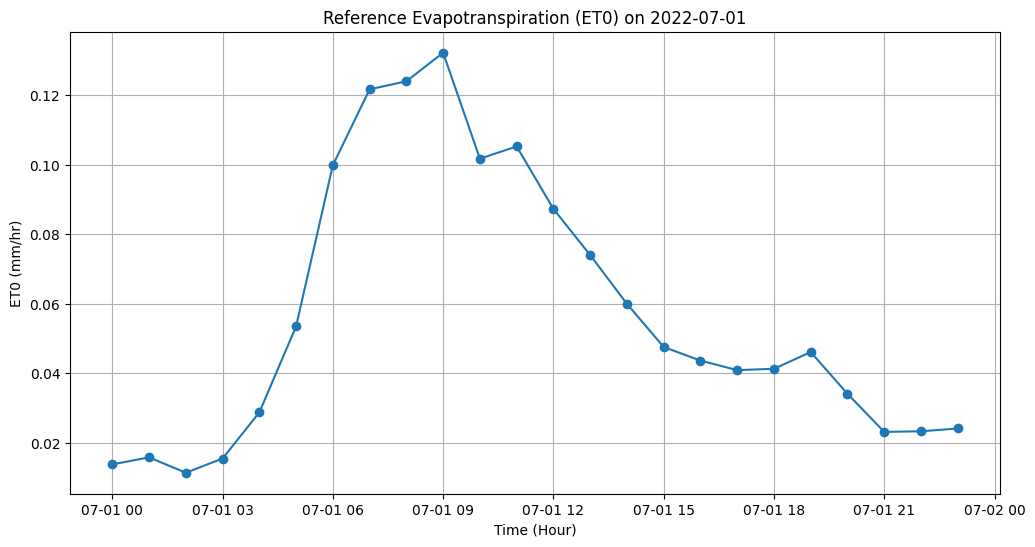

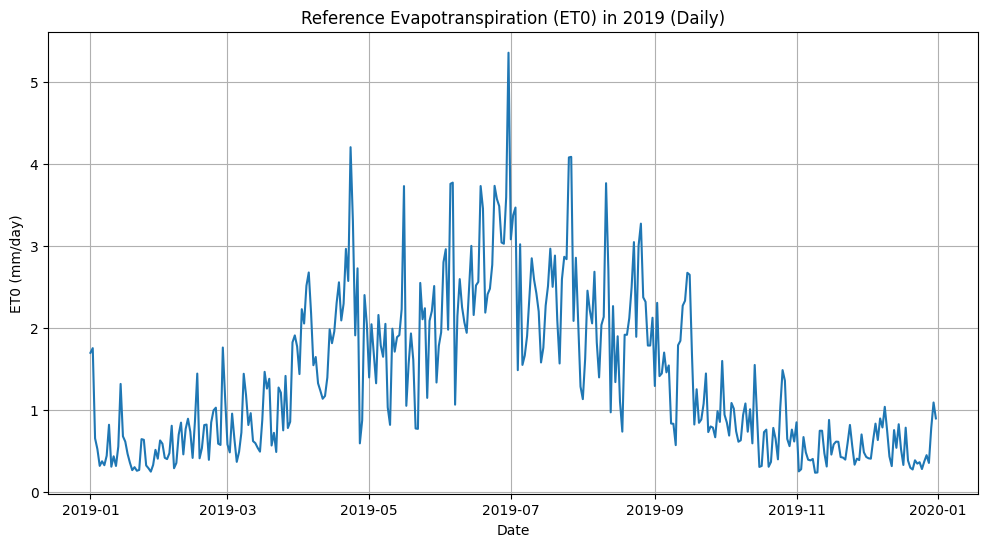

In [13]:
# Plot ET0 for a single day (e.g., July 1, 2022)
single_day = '2022-07-01'
et0_single_day = met_hourly_data.loc[single_day]

plt.figure(figsize=(12, 6))
plt.plot(et0_single_day.index, et0_single_day['ET0'], marker='o', linestyle='-')
plt.xlabel('Time (Hour)')
plt.ylabel('ET0 (mm/hr)')
plt.title(f'Reference Evapotranspiration (ET0) on {single_day}')
plt.grid(True)
plt.show()

# Plot ET0 over the year 2019 (daily aggregation)
et0_2019_daily = met_hourly_data[met_hourly_data.index.year == 2019]['ET0'].resample('D').sum()

plt.figure(figsize=(12, 6))
plt.plot(et0_2019_daily.index, et0_2019_daily.values, linestyle='-')
plt.xlabel('Date')
plt.ylabel('ET0 (mm/day)')
plt.title('Reference Evapotranspiration (ET0) in 2019 (Daily)')
plt.grid(True)
plt.show()

The first graph shows clear trends, that show a higher reference evapotranspiration during the day. This can be explained, by the higher temperature brought forward by the sunny hours of the day. Looking at the yearly graph, we see trends showing that the evapotranspiration becomes higher during the summer. The same reasoning can be used here, with higher temperatures and more sunny weather. 

## Step 3

### Q 5 Plot monthly precipitation and reference evapotranspiration

The reference evapotranspiration shows a clear cyclic pattern of more evapotranspiration in summer and less in winter. The intensity is more or less the same each year. The intensity of rainfall varies every year. Some years are very wet where others are dry. The monthly precipitation also shows genreally tendencies to more water in the summer, but it can also rain a lot in the fall and spring.

The average annual precipitation in denmark is 782 mm/year (2011-2020 average) [https://www.dmi.dk/klima/temaforside-klimaet-frem-til-i-dag/nedbor-og-sol-i-danmark#:~:text=Den%20gennemsnitlige%20%C3%A5rlige%20nedb%C3%B8r%20i,i%201999%20og%20i%202019. , visited 03/05/2026] However the average calculated from the data at the DTU observation station, minimum yerly precipitation is 212 mm in 2028 and the maximum is 762 in 2023. The average of the 10 years measunring time is 532 mm/year. Some areas of Denmark it rans more than other, therefore this seems reasonable.??

52.223749999999995
762.5313888888888
The average annual precipitation is: 532.40 mm/year


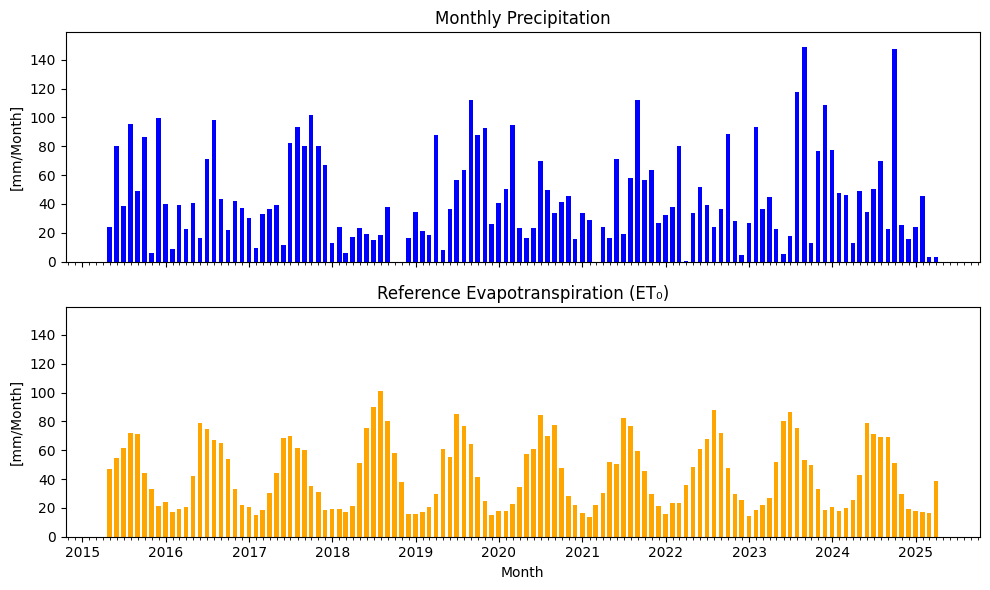

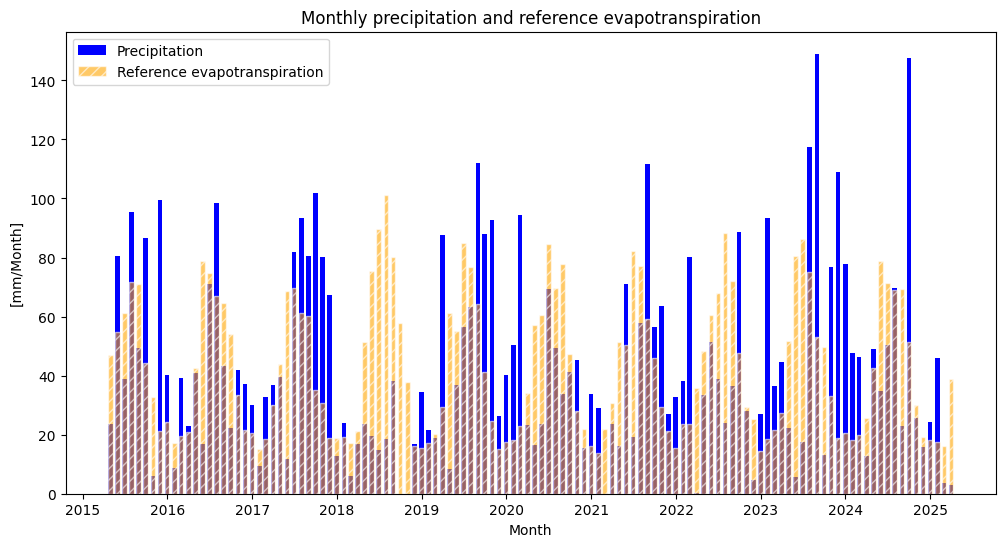

In [14]:
# monthly average of rain intensity (mm/h)
rain_mm_5min = met_data['rain_intensity']*(5/60)
monthly_precipitation = rain_mm_5min.resample('ME').sum()
monthly_ET0 = met_hourly_data['ET0'].resample('ME').sum()

#yearly precipitation
yearly_precipitation = monthly_precipitation.resample('YE').sum()
print(yearly_precipitation.min())
print(yearly_precipitation.max())
print(f'The average annual precipitation is: {yearly_precipitation.sum()/10:.2f} mm/year')

ymax = max(monthly_precipitation.max(), monthly_ET0.max())+10

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
# Precipitation
axes[0].bar(monthly_precipitation.index, monthly_precipitation.values,
            color='blue', width=20)
axes[0].set_ylim(0, ymax)
axes[0].set_ylabel('[mm/Month]')
axes[0].set_title('Monthly Precipitation')

# Reference Evapotranspiration
axes[1].bar(monthly_ET0.index, monthly_ET0.values,
            color='orange', width=20)
axes[1].set_ylim(0, ymax)
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_minor_locator(mdates.MonthLocator())
axes[1].set_xlabel('Month')
axes[1].set_ylabel('[mm/Month]')
axes[1].set_title('Reference Evapotranspiration (ET₀)')

plt.tight_layout()
plt.show()

#plot monthly precipitation in bar chart
plt.figure(figsize=(12, 6))
plt.bar(monthly_precipitation.index, monthly_precipitation.values, color='blue', width=20, label = 'Precipitation' )
plt.bar(monthly_ET0.index, monthly_ET0.values, color ='orange', width = 20, label = 'Reference evapotranspiration', hatch='///', edgecolor='white', alpha=0.6)
plt.xlabel('Month')
plt.ylabel('[mm/Month]')
plt.title('Monthly precipitation and reference evapotranspiration')
plt.legend()
plt.show()

### Q 6 Plot LAI series with 30-day rolling average of air temperature

The plot below shows a clear correlation between seasonal fluctuations of air temeprature and LAI. In areas of dense vegeatation reaching much higher peaks during summertime and dropping to almost the same LAI as sparse vegetation during winter.

This further supports that the limiting factor of LAI changes from light in the winter to water in the summer

During the middle of high temperature periods, a dramatic drop in dense LAI occurs, which may be explained by periods of drought. The dramatic decrease in dense LAI may also be explained by more vegetation having higher evapotranspiration leading to the area reaching wilting conditions faster than sparse vegetation soil.

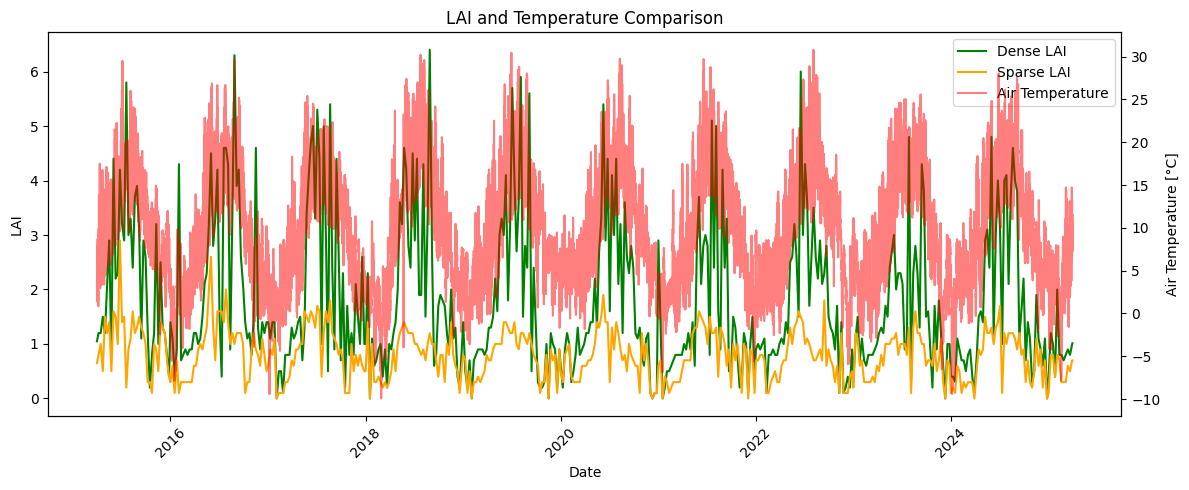

In [15]:
# import LAI data
LAI_data = pd.read_csv('../Background/Data/LAI/lai_series.csv', sep=',')

LAI_data['time'] = pd.to_datetime(LAI_data['time'])
LAI_data = LAI_data.set_index('time')

# defining dense and sparse LAI dataframes
LAI_dense = LAI_data['h18v03_r1008_c1686']
LAI_sparse = LAI_data['h18v03_r1010_c1691']

moving_average_window = 30
temp_moving_average = met_data['air_temperature'].rolling(window=moving_average_window, center=True).mean()

fig, ax1 = plt.subplots(figsize=(12, 5))

# LAI on the left y-axis
ax1.plot(LAI_data.index, LAI_dense, label='Dense LAI', color='green')
ax1.plot(LAI_data.index, LAI_sparse, label='Sparse LAI', color='orange')
ax1.set_xlabel('Date')
ax1.set_ylabel('LAI', color='black')
ax1.tick_params(axis='x', rotation=45)

# Temperature on the right y-axis
ax2 = ax1.twinx()
ax2.plot(temp_moving_average.index, temp_moving_average, label='Air Temperature', color='red', alpha=0.5)
ax2.set_ylabel('Air Temperature [°C]')
ax2.tick_params(axis='y')

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2)

plt.title('LAI and Temperature Comparison')
plt.tight_layout()
plt.show()


### Q 7 Daily time series of basal crop koefficient $K_{cb}$

We are provided the parameters for $K_{cb,ini}$, $K_{cb,end}$ and $K_{cb,min}$ for initial period, end period and bare soil respectively.

To find basal crop coefficient during mid-season $K_{cb, mid}$ we first find basal crop coefficient under full cover $K_{cb,full}$.

The minimum basal crop coeffcient under full cover is only correlated to a crop height parameter:

$$K_{cb, h} = 1.0+0.1 \cdot h \; for \; h \leq 2$$

To find $K_{cb,full}$ we take our minimum coefficient under full cover and account for parameters of:
- mean value wind speed at staion height (10 magl) height, during mid-season $u_2$ in [$m/s$]
- daily mean of minimum relative humidity during the mid-season $RH_{min}$
- mean maximum plant height $h$

$$K_{cb,full} = K_{cb,h}+ \left(0.04\cdot (u_2-2)-0.004 \cdot (RH_{min}-45)\right) \cdot \left(\frac{h}{3}\right)^{0.3}$$

From this the mid-season $K_{cb, mid}$ can be computed in a daily time series:

$$K_{cb,mid} = K_{c,min}+(K_{cb,full}-K_{c,min})(1-\exp(-0.7\cdot LAI))$$

In [16]:
K_cb_ini = 0.3
K_cb_end = 0.3
K_c_min  = 0.175

H_c_values  = [1, 3] #cropheight
colors      = ['steelblue', 'darkgreen']
labels      = ['Sparse', 'Dense']
lai_columns = {1: 'h18v03_r1010_c1691', 3: 'h18v03_r1008_c1686'}

def calculate_Kcb(H_c):

    years = range(met_data.index.year.min(), met_data.index.year.max() + 1)

    #define lists based on time of year
    initial_list, dev_list, mid_list, late_list = [], [], [], [] # create empty list for each period
    for year in years:
        initial_list.append(pd.date_range(start=f"{year}-01-01", end=f"{year}-03-31", freq="D")) # indexes oout the period for each year and adds to list above
        dev_list.append(pd.date_range(start=f"{year}-04-01",     end=f"{year}-04-15", freq="D"))
        mid_list.append(pd.date_range(start=f"{year}-06-01",     end=f"{year}-08-31", freq="D"))
        late_list.append(pd.date_range(start=f"{year}-09-01",    end=f"{year}-10-31", freq="D"))

    initial_dates     = pd.DatetimeIndex([d for r in initial_list for d in r]) # takes the range of each list and adds datetime for each date within that range, for all ranges
    development_dates = pd.DatetimeIndex([d for r in dev_list     for d in r])
    mid_dates         = pd.DatetimeIndex([d for r in mid_list     for d in r])
    late_dates        = pd.DatetimeIndex([d for r in late_list    for d in r])

    met_data['period'] = np.where(met_data.index.isin(initial_dates),     'initial', # assign period attribute to each list of data
                         np.where(met_data.index.isin(development_dates), 'development',
                         np.where(met_data.index.isin(mid_dates),         'mid',
                         np.where(met_data.index.isin(late_dates),        'late',
                         None))))

    # --- Daily resolution ---
    daily_period     = met_data['period'].resample('D').first() # resamples data into daily resolution
    daily_humidity   = met_data['relative_humidity'].resample('D').min()
    daily_wind_speed = met_data['wind_speed_avg'].resample('D').mean()
    daily_LAI        = LAI_data[lai_columns[H_c]].resample('D').mean()

    # --- Daily K_cb ---
    K_cb_h_high      = 1 + 0.1 * np.minimum(2, H_c)
    K_cb_full_daily  = K_cb_h_high + (0.04 * (daily_wind_speed - 2) - 0.004 * (daily_humidity - 45)) * (H_c / 3) ** 0.3
    K_cb_mid_daily   = K_c_min + (K_cb_full_daily - K_c_min) * (1 - np.exp(-0.7 * np.minimum(3, daily_LAI)))

    # --- Daily DataFrame ---
    daily_df = pd.DataFrame({
        'H_c'       : H_c,
        'period'    : daily_period,
        'humidity'  : daily_humidity,
        'wind_speed': daily_wind_speed,
        'LAI'       : daily_LAI,
        'K_cb_full' : K_cb_full_daily,
        'K_cb_mid'  : K_cb_mid_daily,
    })

    return daily_df


# --- Calculate daily DataFrames ---
df_kcb_sparse = calculate_Kcb(H_c=1)
df_kcb_dense  = calculate_Kcb(H_c=3)

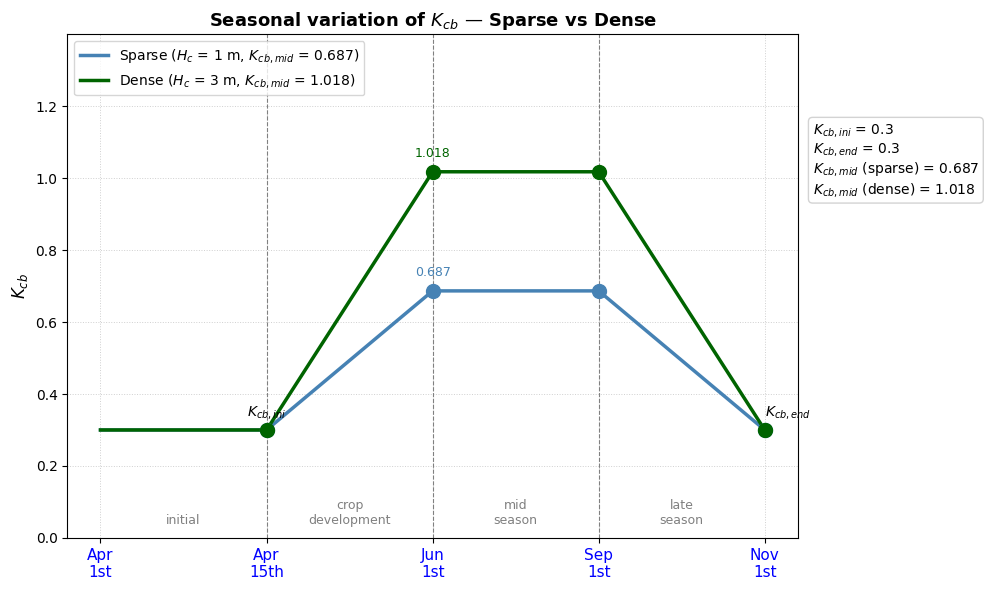

In [17]:
# --- Trapezoid plot: derive period means from daily DataFrame ---
fig, ax = plt.subplots(figsize=(10, 6))

for df, H_c, color, label in zip([df_kcb_sparse, df_kcb_dense], H_c_values, colors, labels):

    # Period averages derived from daily data
    Kcb_mid_val = df[df['period'] == 'mid']['K_cb_mid'].mean()

    x = [0, 1, 2, 3, 4]
    y = [K_cb_ini, K_cb_ini, Kcb_mid_val, Kcb_mid_val, K_cb_end]

    ax.plot(x, y, color=color, linewidth=2.5, zorder=3,
            label=f'{label} ($H_c$ = {H_c} m, $K_{{cb,mid}}$ = {Kcb_mid_val:.3f})')
    for i in [1, 2, 3, 4]:
        ax.plot(x[i], y[i], 'o', color=color, markersize=10, zorder=4)
    ax.text(x[2], Kcb_mid_val + 0.04, f'{Kcb_mid_val:.3f}', ha='center', fontsize=9, color=color)

for xi in [1, 2, 3]:
    ax.axvline(xi, color='gray', linestyle='--', linewidth=0.8)

for xi, lbl in [(0.5, 'initial'), (1.5, 'crop\ndevelopment'),
                (2.5, 'mid\nseason'), (3.5, 'late\nseason')]:
    ax.text(xi, 0.03, lbl, ha='center', va='bottom', fontsize=9, color='gray')

ax.text(1, K_cb_ini + 0.04, '$K_{cb,ini}$', ha='center', fontsize=10, color='black')
ax.text(4, K_cb_end + 0.04, '$K_{cb,end}$', ha='left',   fontsize=10, color='black')

ax.set_ylim(0, 1.4)
ax.set_yticks([0.00, 0.20, 0.40, 0.60, 0.80, 1.00, 1.20])
ax.set_xticks([0, 1, 2, 3, 4])
ax.set_xticklabels(['Apr\n1st', 'Apr\n15th', 'Jun\n1st', 'Sep\n1st', 'Nov\n1st'],
                    color='blue', fontsize=11)
ax.set_ylabel('$K_{cb}$', fontsize=12)
ax.set_title('Seasonal variation of $K_{cb}$ — Sparse vs Dense', fontsize=13, fontweight='bold')
ax.grid(True, linestyle=':', linewidth=0.7, alpha=0.6)

annotation = f'$K_{{cb,ini}}$ = {K_cb_ini}\n$K_{{cb,end}}$ = {K_cb_end}\n'
for df, lbl in zip([df_kcb_sparse, df_kcb_dense], labels):
    val = df[df['period'] == 'mid']['K_cb_mid'].mean()
    annotation += f'$K_{{cb,mid}}$ ({lbl.lower()}) = {val:.3f}\n'
ax.text(1.02, 0.75, annotation.strip(), transform=ax.transAxes, fontsize=10, va='center',
        bbox=dict(boxstyle='round', facecolor='white', edgecolor='lightgray'))

ax.legend(loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()

$K_{cb,mid}$ and $K_{cb,full}$ are plotted as daily time series across all years. Showing the yearly seasonality across dense and sparse vegetation areas. We see that dense vegetation $K_{cb,mid}$ are much closer to reaching $K_{cb,full}$ compared to sparse vegetation during summertime, as expected.

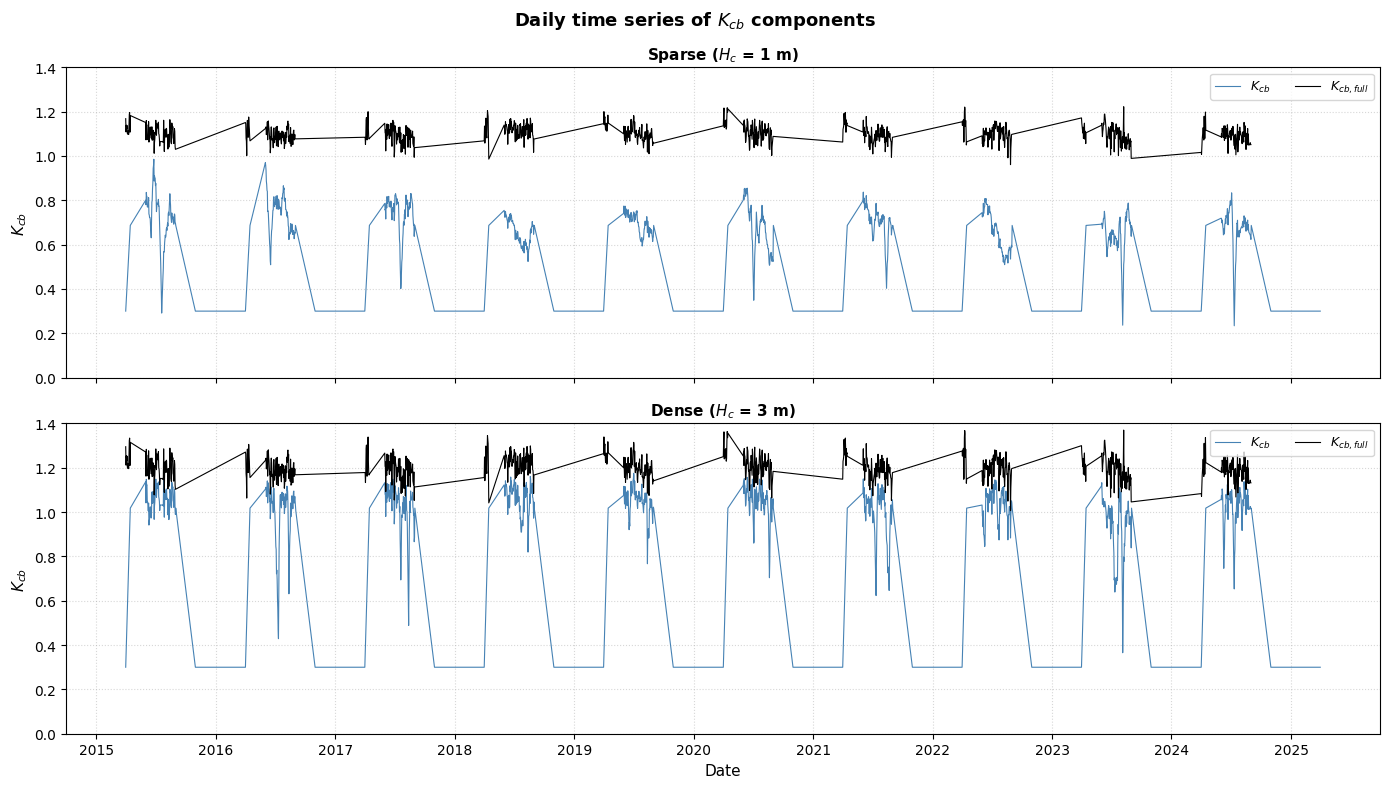

In [18]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

for ax, df, H_c, label in zip(axes, [df_kcb_sparse, df_kcb_dense], H_c_values, labels):

    df = df[df['period'].notna()]

    Kcb_mid_val = df[df['period'] == 'mid']['K_cb_mid'].mean()

    # Build continuous daily Kcb series following trapezoid shape
    kcb_daily = pd.Series(index=df.index, dtype=float)

    for period, group in df.groupby(df.index.year):
        df_ini  = group[group['period'] == 'initial']
        df_dev  = group[group['period'] == 'development']
        df_mid  = group[group['period'] == 'mid']
        df_late = group[group['period'] == 'late']

        # Initial: flat at K_cb_ini
        kcb_daily[df_ini.index]  = K_cb_ini

        # Development: linear ramp from K_cb_ini to K_cb_mid
        if len(df_dev) > 0:
            ramp_up = np.linspace(K_cb_ini, Kcb_mid_val, len(df_dev))
            kcb_daily[df_dev.index] = ramp_up

        # Mid: daily computed K_cb_mid values
        kcb_daily[df_mid.index]  = df_mid['K_cb_mid'].values

        # Late: linear ramp down from K_cb_mid to K_cb_end
        if len(df_late) > 0:
            ramp_down = np.linspace(Kcb_mid_val, K_cb_end, len(df_late))
            kcb_daily[df_late.index] = ramp_down

    ax.plot(kcb_daily.index, kcb_daily, color='steelblue', linewidth=0.8, label='$K_{cb}$')
    ax.plot(df[df['period'].isin(['development', 'mid'])].index,
            df[df['period'].isin(['development', 'mid'])]['K_cb_full'],
            color='black', linewidth=0.8, label='$K_{cb,full}$')

    ax.set_ylabel('$K_{cb}$', fontsize=11)
    ax.set_title(f'{label} ($H_c$ = {H_c} m)', fontsize=11, fontweight='bold')
    ax.legend(loc='upper right', fontsize=9, ncol=4)
    ax.grid(True, linestyle=':', alpha=0.5)
    ax.set_ylim(0, 1.4)

axes[-1].set_xlabel('Date', fontsize=11)
fig.suptitle('Daily time series of $K_{cb}$ components', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### Q 8 Plot daily time series of $f_{ew}$

The upper energy limit of basal crop coeffcient is found by the daily maximum value between two caluclations:

$$K_{c,max} = \max\left(\left(1.2 + \left(0.04 \cdot (u_2 - 2) - 0.004 \cdot (RH_{min} - 45)\right) \cdot \left(\frac{H_c}{3}\right)^{0.3}\right), \left(K_{cb} + 0.05\right)\right)$$

From this the soil fraction covered by vegetation is computed with defined basal crop koeffcients from Q7:

$$f_c = \left(\frac{K_{cb} - K_{c,min}}{K_{c,max} - K_{c,min}}\right)^{(1 + 0.5 \cdot H_c)}$$

We may now compute fraction of exposed wetted soil $f_{ew}$:

$$f_{ew} = 1 - f_c$$

From the plot we see that a larger fraction of the wetted soil is exposed during winter where there are less leafs. During winter $f_{ew}$ is similar between dense and sparse vegetation which aligns with our previous fidnings of similar $LAI$ between sparse and dense during winter periods.

Additionally we see a discrepancy in $f_{ew}$ between areas during summertime with it being lower for dense areas, again aligning with the higher $LAI$ in dense areas discovered above.

We thereby see an inverse relationship between $LAI$ and $f_{ew}$.

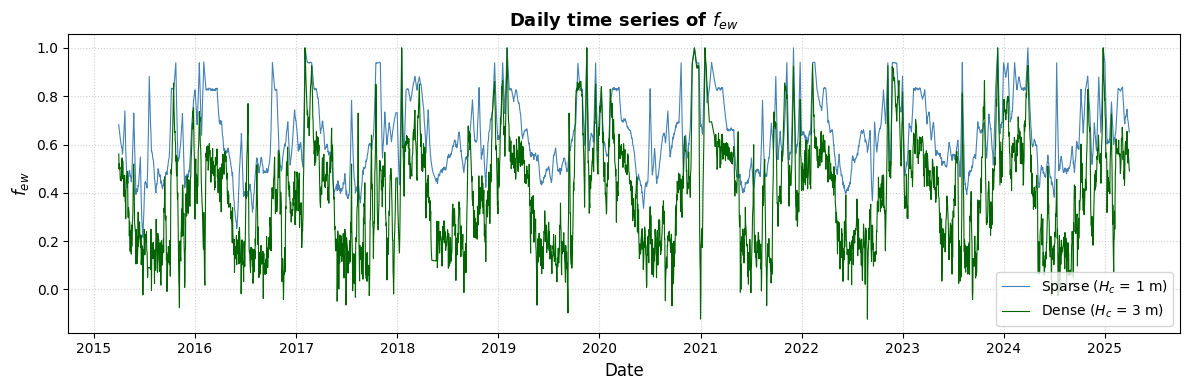

In [19]:
def calculate_kcmax_few(df_kcb, H_c):
    #redefine, is also defined in Q8
    daily_humidity   = met_data['relative_humidity'].resample('D').min()
    daily_wind_speed = met_data['wind_speed_avg'].resample('D').mean()
    
    expr = (0.04 * (daily_wind_speed - 2) - 0.004 * (daily_humidity - 45)) * (H_c / 3) ** 0.3

    K_c_max  = np.maximum(1.2 + expr, df_kcb['K_cb_mid'] + 0.05)

    #fraction covreed by vegetation
    fc       = (df_kcb['K_cb_mid'] - K_c_min) / (K_c_max - K_c_min) ** (1 + 0.5 * H_c)
    daily_few = 1 - fc

    return K_c_max, daily_few

K_c_max_sparse , few_sparse  = calculate_kcmax_few(df_kcb_sparse, H_c=1)
K_c_max_dense  ,  few_dense  = calculate_kcmax_few(df_kcb_dense,  H_c=3)

#define values in df: 
df_kcb_sparse['f_ew'] = few_sparse
df_kcb_dense['f_ew'] = few_dense

df_kcb_sparse['K_c_max'] = K_c_max_sparse
df_kcb_dense['K_c_max'] = K_c_max_dense


fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(few_sparse.index, few_sparse, color='steelblue', linewidth=0.8, label='Sparse ($H_c$ = 1 m)')
ax.plot(few_dense.index,  few_dense,  color='darkgreen', linewidth=0.8, label='Dense ($H_c$ = 3 m)')
ax.set_ylabel('$f_{ew}$', fontsize=12)
ax.set_xlabel('Date', fontsize=12)
ax.set_title('Daily time series of $f_{ew}$', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

### Q 9 Daily time series of soil evaporation coeffcients $K_e$ in the upper soil zone for 2019

We know the following soil zone parameters:
- Soil type: Silt loam
- Field capacity: $\theta_{FC} = 28 \: \%$
- Wilting point: $\theta_{WP} = 15 \: \%$
- Upper soil zone: $Z_e = 10 \: cm$

From Table 19 under silt loam we see the empirical values:
- Total evaporable water $TEW = 18-25 \: mm$
- Readily evaporable water $REW: 8-11 \: mm$

From this we may firstly compute the soil evaporation reduction coeffcient $K_r$ to explain how soil evaporation decreases as topsoil is depleted (dried out):

$$K_r = \frac{TEW - \max(D_e, REW)}{TEW - REW}$$

With this the soil evaporation coeffcient $K_e$ may be computed to express the evaporation component of exposed wet soil:

$$K_e = \min\left(K_r \cdot (K_{c,max} - K_{cb}),\ f_{ew} \cdot K_{c,max}\right)$$

Now evaporation $E_i$ may be computed:

$$E = K_e(K_r)ET_0 $$

Perculation $DP_{e,i}$ is computed to express any water in the soil above saturation that is assumed to percolate:

$$DP_{e,i} = P_i - De_{e,i}$$

Now the updated soil depletion $De_i$ can be computed for both areas:

$$De_i = De_{e,i-1} -(P_i - RO_i) + \frac{E_i}{f_{ew,i}} + T_{ew,i} + DP_{e,i}$$

Runoff is assumed to be neglient such that $RO_i = 0$

The correlation between evaporation reduction coefficient and topsoil dpeletion $D_e$ may be expressed with arbitrary ranges below for better understanding.

In [20]:
#define empty datafram for year 2019:
df_sparse_2019 = pd.DataFrame(index=pd.date_range(start='2019-01-01', end='2019-12-31', freq='D'))
df_dense_2019  = pd.DataFrame(index=pd.date_range(start='2019-01-01', end='2019-12-31', freq='D'))

#define precipitation and reference evapotranspiration
df_sparse_2019['precip'] = rain_mm_5min[rain_mm_5min.index.year == 2019].resample('D').sum()
df_sparse_2019['ET0']    = met_hourly_data[met_hourly_data.index.year == 2019]['ET0'].resample('D').sum()
df_dense_2019['precip']  = df_sparse_2019['precip']
df_dense_2019['ET0']     = df_sparse_2019['ET0']

#define dataframes of kcb values to contain data for 2019
df_kcb_sparse_2019 = df_kcb_sparse[df_kcb_sparse.index.year == 2019]
df_kcb_dense_2019  = df_kcb_dense[df_kcb_dense.index.year == 2019]

df_dense_2019['K_cb_full']     = df_kcb_dense_2019['K_cb_full']
df_dense_2019['K_cb_mid']      = df_kcb_dense_2019['K_cb_mid']
df_dense_2019['f_ew']          = df_kcb_dense_2019['f_ew']
df_dense_2019['K_c_max']       = df_kcb_dense_2019['K_c_max']

df_sparse_2019['K_cb_full']    = df_kcb_sparse_2019['K_cb_full']
df_sparse_2019['K_cb_mid']     = df_kcb_sparse_2019['K_cb_mid']
df_sparse_2019['f_ew']         = df_kcb_sparse_2019['f_ew']
df_sparse_2019['K_c_max']      = df_kcb_sparse_2019['K_c_max']

In [21]:
# define values given in assingment
teta_fc = 0.28
teta_wp = 0.15
Z_e = 0.1 #m

# calculate TEW and REW
TEW = 1000 * (teta_fc - 0.5 * teta_wp) * Z_e
print(f"Total Evaporable Water (TEW) = {TEW:.2f} mm")
REW = 8  # mm, from figure in slide 32
print(f"Readily Evaporable Water (REW) = {REW:.2f} mm")


dfs = [(df_sparse_2019), 
       (df_dense_2019)]

for df in dfs:
    De = 0 # i-1
    for idx, col in df.iterrows(): #beregner for i = i

        Kr     = (TEW - np.maximum(De, REW)) / (TEW - REW) #calculate Kr (evaporation reduction coeff)
        Kr     = np.clip(Kr,0.0,1.0)
        Ke     = np.minimum(Kr * (col['K_c_max'] - col['K_cb_mid']) , col['f_ew'] * col['K_c_max'])
        Ke     = np.clip(Ke,0.0,1.0) #calculate Ke (evaporation coeff)
        E      = Ke*col['ET0'] #calculate evaporation
        DP     = np.maximum(col['precip'] - De,0)
        De     = De - col['precip'] + (E/col['f_ew']) + DP
        De     = np.clip(De,0.0,TEW)
        #np.minimum(np.maximum(De, 0), TEW)  # clip between 0 and TAW - Depletion cannot be negative and water above wilting point will leave the root zone

        df.loc[idx, 'Kr']     = Kr
        df.loc[idx, 'Ke']     = Ke
        df.loc[idx, 'E']      = E 
        df.loc[idx, 'DP_evap']= DP
        df.loc[idx, 'De']     = De

#display(df_sparse_2019['De'])
#display(df_dense_2019['De'])

Total Evaporable Water (TEW) = 20.50 mm
Readily Evaporable Water (REW) = 8.00 mm


Finally three daily time step plots are produced showing $K_e$ for dense and sparse vegetation areas over time with precipitation, evaporation and soil depletion for each area respectively.

Across 2019 sparse vegetation areas shows the highest $K_e$ except for winter months where $LAI$ is near none and the wetted soil fraction remain nearly the same in both areas, resultiung in similar $K_e$.

$K_e$ starts high during winter, then drops during spring where blooming occurs lowering $f_{ew}$ in both areas. Short term spikes in $K_e$ are seen during and immediately after spatial precipitation events in the summer, then slowly increases throughout autumn with consistent precipitation and remains high during winter.

Sparse areas having higher and more evaporation during summer with similar evaporation in winter. Evaporation koeffcicient states that winter causes conditions for high evaporation, but low solar energy and meterological conditions result in much lower actual evaporation. There is generally a small time lag between precipitation events and peak evaporation.

Soil water depletion is similar for both areas, however sparse areas does reach slighty higher extremes during summer follwing precipitation events, compared to dense areas.

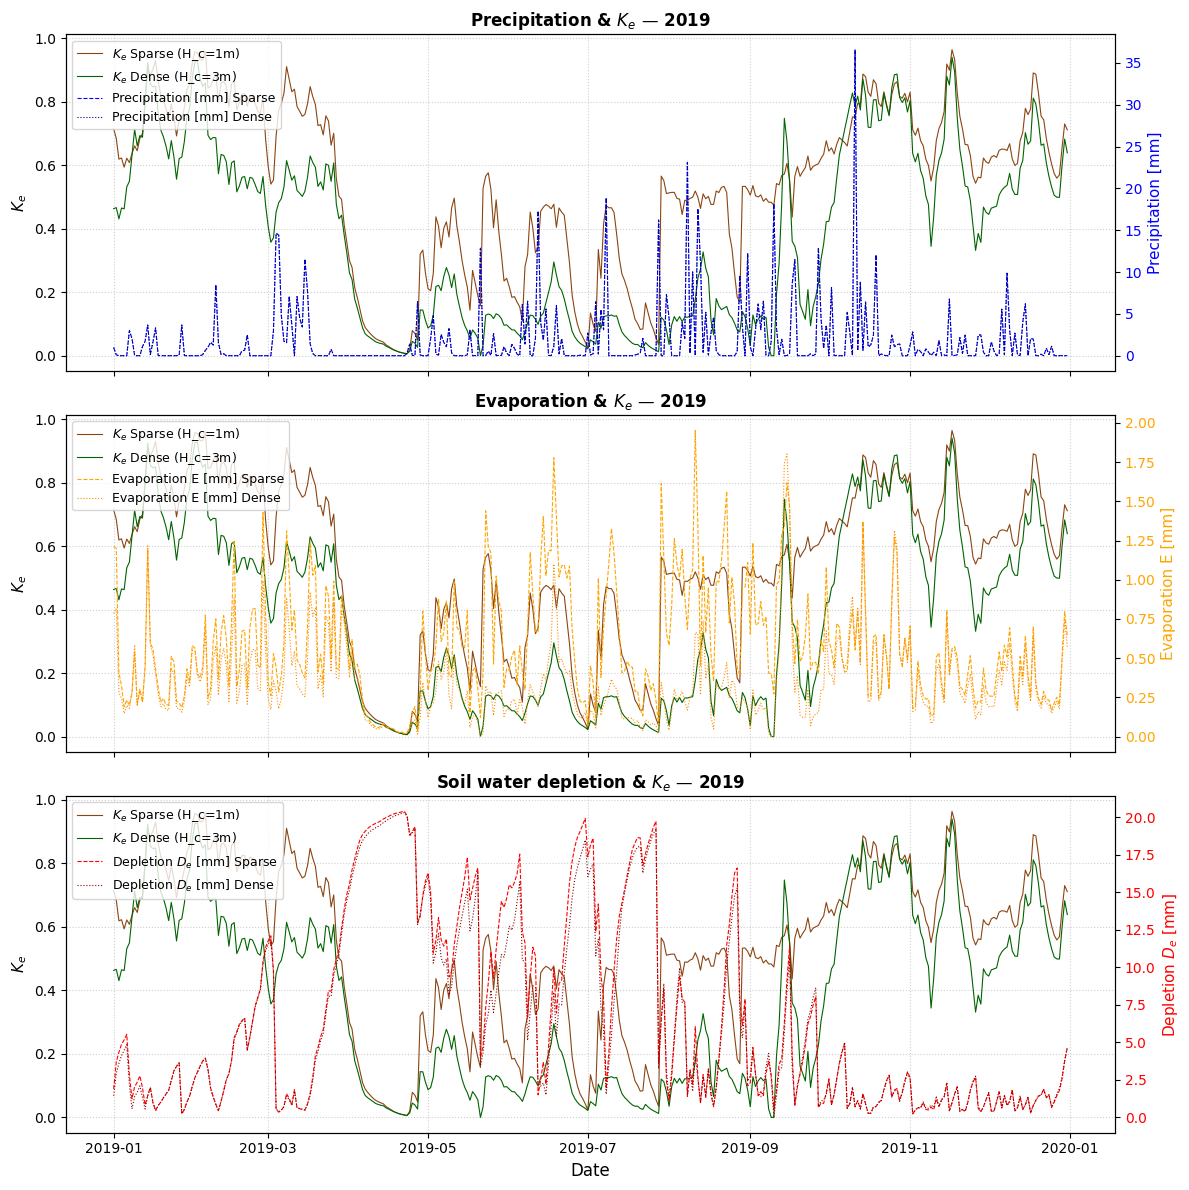

In [22]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 12), sharex=True)

# change colors or seperate into two graphs - one dense and one sparse

plot_configs = [
    (ax1, df_sparse_2019['precip'],       df_dense_2019['precip'],       'Precipitation [mm]',  'blue',   'Precipitation & $K_e$ — 2019'),
    (ax2, df_sparse_2019['E'],            df_dense_2019['E'],            'Evaporation E [mm]',  'orange', 'Evaporation & $K_e$ — 2019'),
    (ax3, df_sparse_2019['De'],  df_dense_2019['De'],  'Depletion $D_e$ [mm]','red',    'Soil water depletion & $K_e$ — 2019'),
]

for ax, data_sparse, data_dense, data_label, data_color, title in plot_configs:

    # --- Left axis: K_e ---
    ax.plot(df_sparse_2019.index, df_sparse_2019['Ke'], color='saddlebrown', linewidth=0.8, label='$K_e$ Sparse (H_c=1m)')
    ax.plot(df_dense_2019.index,  df_dense_2019['Ke'],  color='darkgreen',   linewidth=0.8, label='$K_e$ Dense (H_c=3m)')
    ax.set_ylabel('$K_e$', fontsize=11)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.set_title(title, fontsize=12, fontweight='bold')

    # --- Right axis: sparse and dense ---
    ax_r = ax.twinx()
    ax_r.plot(data_sparse.index, data_sparse, color=data_color,  linewidth=0.8, label=f'{data_label} Sparse', linestyle='--')
    ax_r.plot(data_dense.index,  data_dense,  color='dark' + data_color,  linewidth=0.8, label=f'{data_label} Dense',  linestyle=':')
    ax_r.set_ylabel(data_label, fontsize=11, color=data_color)
    ax_r.tick_params(axis='y', labelcolor=data_color)

    # --- Combined legend ---
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax_r.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, fontsize=9, loc='upper left')

ax3.set_xlabel('Date', fontsize=12)
plt.tight_layout()
plt.show()

A high (1) $K_e$-value indicates a lot of readily available evapotory water on the surface. This is true right after a precipitation event. After the event, the water will start to evaporate, resulting in a lowering of the $K_e$ value. When it reaches 0, there is no more evaporable water on the surface to evaporate. 

On the first plot, we see that when precipitation occurs, the $K_e$ value increases. The area with sparse vegetation is more sensitive to changes in precipitation, during the summer period.

On the second plot, we see the evaporation and $K_e$ values. We see that the rises in the dry periods, right after rain. The evaporation is much smaller on the densly vegitated area.

On the third plot, we see that the soil water depletion ($D_e$) follows a similar trend for both dense and sparse areas. It follows the pattern of reducing when precipitation events occour, and in dry periods it increases to maximum (TEW).

### Q 10 Daily time series of actual evapotranspiration $ET_{act}$ from upper soil depletion and root zone

We are given the followng conditions:
- Root zone depth sparse: $Z_{r, sparse} = 0.5 \: m$
- Root zone depth dense: $Z_{r, dense} = 1.6 \: m$
- Readily availaible water for transpiration in the root zone without water stress: $p = 50 \: \%$

<br>
To find actual evapotranspiration in the root zone, we do largely the same steps as in Q10.
<br><br><br>
Instead of table values we calculate total availiable water (TAW) and readily availiable water (RAW) for each areas root zone:

$$ TAW = 1000 \cdot (\theta_{FC} - \theta_{WP}) \cdot Z_{r,sparse}$$

$$ RAW = p \cdot TAW $$

If the p-value is unknown, a p-value of 50% is commonly used.

<br><br>
For the daily time series the starting soil depletion is set to $D_{r,i-1} = 0$
<br><br>
Firstly the water stress coeffcient $K_s$ is computed. It is constrained within and index of 0-1 where 1 indicates no water stress meanning $D_r \leq RAW$ and 0 indicates complete stress with no transpiration $Dr = RAW$:
<br><br>
$$ K_{s,i} = \frac{TAW - max(D_{r,i} \: , \: RAW)}{TAW - RAW} $$
<br><br>
With the known reference evapotranspiration ($ET_0$) and basal crop koeffcient ($K_{cb, mid}$) calculated above, the transpiration is computed:
<br><br>
$$ T_i = K_{s,i} K_{cb,i} ET_{0,i} $$
<br><br>
With both transpitation and evaporation being defined, actual evapotranspiration ($ET_{act,i}$ [mm]) can be computed as:
<br><br>
$$ ET_{act,i} = E_i + T_i $$
<br><br>
To compute percolation ($DP_{r,i}$) it is assumed that the root zone is so deep that only water that did not evaporate in the topsoil will percolate to the root zone, such that:
<br><br>
$$ DP_{r,i} = P_i - Dr_{i-1} - ET_{act,i} $$
<br><br>
The root zone depletion is then updated with the computed parameters:
<br><br>
$$ Dr_i = Dr_{i-1} - (P_i - RO_i) + ET_{act,i} + DP_{r,i} $$

Note that, as previously, runoff is assumed to be neglible such that $RO_i = 0$

In [ ]:
p = 0.5

Z_r_sparse = 0.5 # root zone depth [m]
Z_r_dense = 1.6 # root zone depth [m]

TAW_sparse = 1000 * (teta_fc - teta_wp) * Z_r_sparse
TAW_dense = 1000 * (teta_fc - teta_wp) * Z_r_dense

RAW_sparse = p * TAW_sparse
RAW_dense  = p * TAW_dense

print(f"Total Available Water (TAW_sparse) = {TAW_sparse:.2f} mm")
print(f"Total Available Water (TAW_dense) = {TAW_dense:.2f} mm")
print(f"Readily Available Water (RAW_sparse) = {RAW_sparse:.2f} mm")
print(f"Readily Available Water (RAW_dense) = {RAW_dense:.2f} mm")

Total Available Water (TAW_sparse) = 65.00 mm
Total Available Water (TAW_dense) = 208.00 mm
Readily Available Water (RAW_sparse) = 32.50 mm
Readily Available Water (RAW_dense) = 104.00 mm


In [24]:
dfs = [(df_sparse_2019, TAW_sparse, RAW_sparse), 
       (df_dense_2019,  TAW_dense,  RAW_dense)]

for df, TAW, RAW in dfs:

    Dr = 0

    for idx, col in df.iterrows():

        Ks     = (TAW - np.maximum(Dr, RAW)) / (TAW - RAW)
        T      = Ks * col['K_cb_mid'] * col['ET0']
        ET_act = col['E'] + T
        DP     = np.maximum(col['precip'] - Dr - ET_act, 0)
        Dr     = Dr - col['precip'] + ET_act + DP
        Dr     = np.minimum(np.maximum(Dr, 0), TAW)  # clip between 0 and TAW - Depletion cannot be negative and water above wilting point will leave the root zone

        df.loc[idx, 'Ks']     = Ks
        df.loc[idx, 'T']      = T
        df.loc[idx, 'ET_act'] = ET_act
        df.loc[idx, 'DP_trans']     = DP
        df.loc[idx, 'Dr']     = Dr

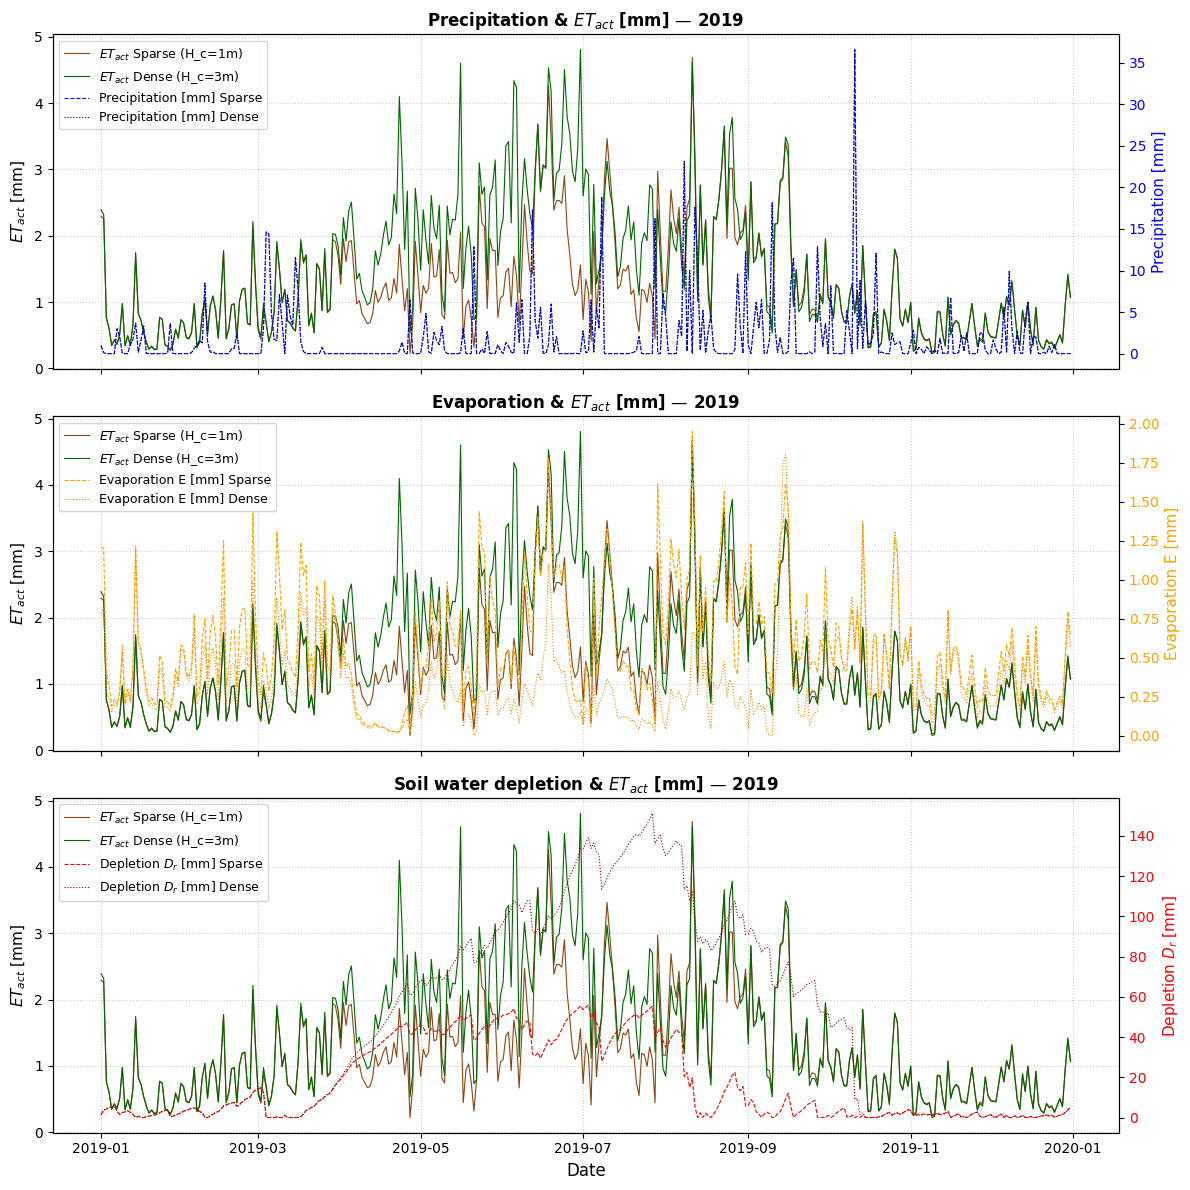

In [25]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 12), sharex=True)

# change colors or seperate into two graphs - one dense and one sparse

plot_configs = [
    (ax1, df_sparse_2019['precip'],       df_dense_2019['precip'],       'Precipitation [mm]',  'blue',   'Precipitation & $ET_{act}$ [mm] — 2019'),
    (ax2, df_sparse_2019['E'],            df_dense_2019['E'],            'Evaporation E [mm]',  'orange', 'Evaporation & $ET_{act}$ [mm] — 2019'),
    (ax3, df_sparse_2019['Dr'],  df_dense_2019['Dr'],  'Depletion $D_r$ [mm]','red',    'Soil water depletion & $ET_{act}$ [mm] — 2019'),
]

for ax, data_sparse, data_dense, data_label, data_color, title in plot_configs:

    # --- Left axis: K_e ---
    ax.plot(df_sparse_2019.index, df_sparse_2019['ET_act'], color='saddlebrown', linewidth=0.8, label='$ET_{act}$ Sparse (H_c=1m)')
    ax.plot(df_dense_2019.index,  df_dense_2019['ET_act'],  color='darkgreen',   linewidth=0.8, label='$ET_{act}$ Dense (H_c=3m)')
    ax.set_ylabel('$ET_{act}$ [mm]', fontsize=11)
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.set_title(title, fontsize=12, fontweight='bold')

    # --- Right axis: sparse and dense ---
    ax_r = ax.twinx()
    ax_r.plot(data_sparse.index, data_sparse, color=data_color,  linewidth=0.8, label=f'{data_label} Sparse', linestyle='--')
    ax_r.plot(data_dense.index,  data_dense,  color='dark' + data_color,  linewidth=0.8, label=f'{data_label} Dense',  linestyle=':')
    ax_r.set_ylabel(data_label, fontsize=11, color=data_color)
    ax_r.tick_params(axis='y', labelcolor=data_color)

    # --- Combined legend ---
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax_r.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, fontsize=9, loc='upper left')

ax3.set_xlabel('Date', fontsize=12)
plt.tight_layout()
plt.show()

In Q9, we saw that the sparse vegitation had a higher $K_r$ value in generel. When it comes to evapotranspiration, we see that the densely vegitated area generally has a higher evapotranspiration. The few times that the sparse vegetation has a higher evapotranspiration, happens when a long dry period has depleted the rootzones, and a precipitation event happens. 



## Step 4

### Q11a)


Now, we pressume that the only water that wettens the soil is infiltatrion, and therefore no longer assumed that all precipitation wettens the soil. Infiltration can defined based on precipitation and runoff: 
$$I_i = P_i - RO_i$$

Hence, we subsitute ($P_i - RO_i$) with $I_i$ in the water balance equations from Q9 and Q10

*Soil evaporation water balance*
$$DP_{e,i} = I_i - De_{e,i}$$
Now the updated soil depletion $De_i$ can be computed for both areas:
$$De_i = De_{e,i-1} - I_i + \frac{E_i}{f_{ew,i}} + T_{ew,i} + DP_{e,i}$$

*Root zone transpiration, water balance*
$$ DP_{r,i} = I_i - Dr_{i-1} - ET_{act,i} $$

The root zone depletion is then updated with the computed parameters:

$$ Dr_i = Dr_{i-1} - I_i + ET_{act,i} + DP_{r,i} $$

##### **Green Ampt Model**

$$
I = K (1+\frac{\psi \Delta \theta}{I_c})
$$

Difference in soil water content across the wetting front: if $\Delta \theta$ is big, the soil is dry and can absorb much water. if it is wet, the soil is already wet
$$\Delta \theta = \theta_0 - \theta_{current}$$
- $\theta_0$ initial water content
- $\theta_{current}$ is the currently available water in the root zone, which can be found by:

$$\theta_{current} = \theta_{FC}-\frac{D_r}{Z_r}$$
- $\theta_{FC}$ is the field capacity (the point, where water does not move down by graity), which is known from Q9. 
- $D_r$ = root zone depletion [mm], which describes how much water has been drained from soil by evapotranspiration beyond field capacity
- $Z_r$ = root zone depth [mm] (given in Q 10)

Infiltration cannot the precipitation rate $P_t$ $min(I_t,P_t)$

$$I_{act}\cdot \Delta t = \Delta I_c$$

$$I_{c,t} = I_{c,t-1}+I_{act,t} + \cdot \Delta t - ET_{act,t} $$

### Q11b) Compute actual evaporation and infiltration for your time series

To compute evapotranspiration and infiltration for our time series precipitation is defined in 5 minute steps from meterological datset. Koefficients $K_s$, $K_{cb, mid}$ and $K_e$ are used in dailty time steps as fluctuation is negitable for the small resolution. 

For more fluctuating data such as reference evapotranspoiration $ET0$ hourly time steps are used to derive hourly transpiration and evaporation and lastly compute actual evapotranspiration $ET_{act}$ and converted to $mm / 5 min$. 

These are used in smaller resolution due to their dependance on meterological factors that fluctuate greately throughout same day and multi-day time scales.

From this the Green Ampt Long-Term model may be used with the equaitons described above.

A physical limit is set such that no evapotranspiration occurs if current saturation is below wilting point.

A condition for actual infiltration is set such that if it becomes negative the infiltration is set to soil conductivity $K_{sat}$.
This is to avoid division by 0 in the Green Ampt infiltration model and infite potential infiltration. Therefore when soil is dry the absorption of the soil is set to silty loam's empirically derived gravitational conductivity of $K_{sat}$.

Actual infiltration is also set to not exceed precipitation during the same time step and potential infiltration to never be negative as these are physcial impossibilities.

In [26]:
dfs = [df_sparse_2019, df_dense_2019]

# Table values - Silt Loam
dt = 5 #min
theta_fc = 0.28
theta_wp = 0.15
theta_s = 0.485
K_sat = 0.65 * 10 * dt/60 # convert from cm/h to mm/5 min
psi = 16.68 * 10 # convert from cm to mm

for df in dfs:

    df['Z_r'] = Z_r_sparse if df is df_sparse_2019 else Z_r_dense

    common_index = met_data['rain_intensity'][met_data.index.year == 2019].index

    precip_5min = met_data['rain_intensity'].reindex(common_index, method='ffill').values * dt/60

    df_hourly     = df.reindex(met_hourly_data.index, method='ffill')
    T_hourly      = (df_hourly['Ks'] * df_hourly['K_cb_mid'] * met_hourly_data['ET0']).fillna(0)
    E_hourly      = (df_hourly['Ke'] * met_hourly_data['ET0']).fillna(0)
    ET_act_hourly = T_hourly + E_hourly

    ET_act_5min  = ET_act_hourly.resample('5Min').ffill().reindex(common_index, method='ffill')
    ET_act_5min = ET_act_5min * dt/60
    ET_act_5min = ET_act_5min.values.copy()

    Dr_5min  = df['Dr'][df.index.year == 2019].resample('5Min').ffill().reindex(common_index, method='ffill').values
    Z_r_5min = df['Z_r'][df.index.year == 2019].resample('5Min').ffill().reindex(common_index, method='ffill').values * 1e3 #convert from m to mm

    theta_current_5min = theta_fc - (Dr_5min / Z_r_5min)
    delta_theta = theta_s - theta_current_5min

    n     = len(common_index)
    I_c   = np.zeros(n) #cumalitivt infiltration til tid
    I_act = np.zeros(n) # actual infiltration at timestep
    I     = np.zeros(n)

    for i in range(1, n):

        if theta_current_5min[i] < theta_wp:
            ET_act_5min[i] = 0

        # 1. Compute I using PREVIOUS I_c — delta_theta differs between sparse/dense here
        if I_c[i-1] <= 0:
            I[i] = K_sat
        else:
            I[i] = K_sat * (1 + (psi * delta_theta[i]) / I_c[i-1])

        # 2. Cap by precip
        I_act[i] = np.minimum(precip_5min[i], I[i])

        # 3. Update I_c with current I_act
        I_c[i] = np.maximum(I_c[i-1] + I_act[i] - ET_act_5min[i], 0)

    I_5min = pd.Series(I_act, index=common_index)
    I_daily = pd.Series(I_act, index=common_index).resample('D').sum()
    df['Infiltration'] = I_daily
    #display(df['Infiltration'])

    if df is df_sparse_2019:
        I_5min_sparse = I_5min
        ET_act_5min_sparse = ET_act_5min
        Dr_5min_sparse = Dr_5min
        
    else:
        I_5min_dense = I_5min
        ET_act_5min_dense = ET_act_5min
        Dr_5min_dense = Dr_5min

### Q11c) Plot precipitation, root zone depletion, actual evapotranspiration, infiltration and runoff as time series in a single figure for the year 2019.

We see the largest root zone depletion during the summer months, where the zones experience seasonal vegetation, which in turn gives a larger transporation. The evaporation also increases during the summer, due to increased temperatures. The summer also includes fewer precipitation events, especially during the summer of 2019, as it was a very warm year. The sparse vegetation peaks around a root zone depletion of 60 mm, while dense vegetation peaks around 120 mm.

We see that the system responds to large precipitation events, by showing large drops in the root zone depletion. Depending on the intensity of the event, we also see a lot of the precipitation ending as runoff, even though the root zone depletion remains high. This shows that too much water at a short interval, will result in runoff, rather than saturating the soil.

Apart from the summer season, we see that the root zone depletion remains fairly low. Outside of the summer season, the vegetation no longer requires the same amount of water, as it no longer need to without its leafs. The temperature also drops, which results in lower evaporation overall.

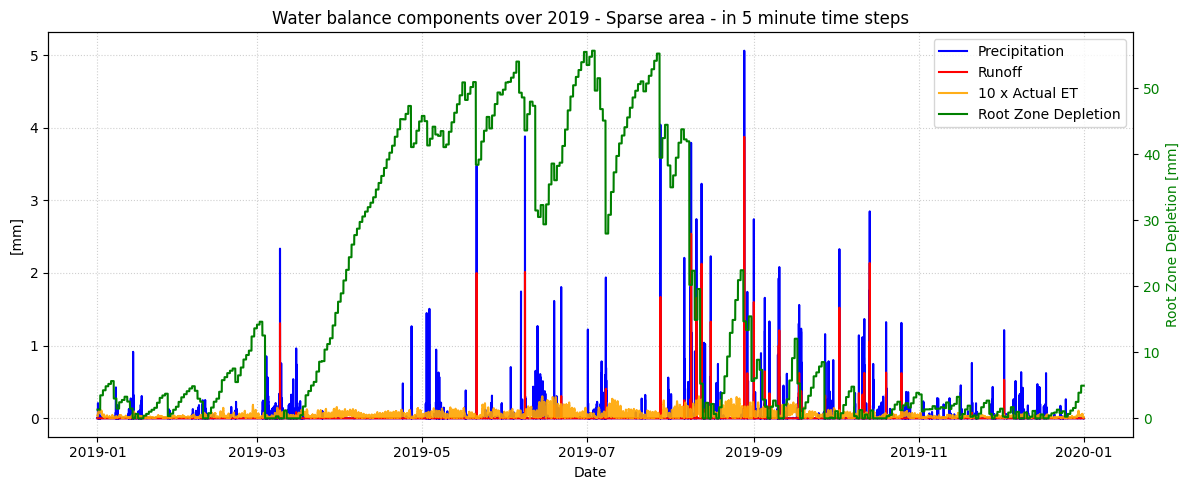

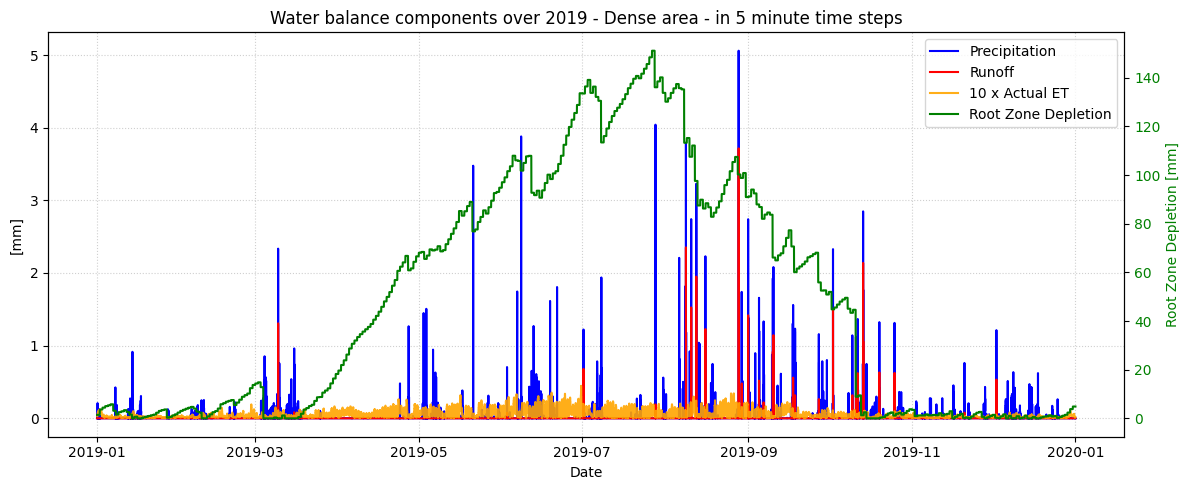

In [27]:
for df in dfs:

    I = I_5min_sparse if df is df_sparse_2019 else I_5min_dense
    ET_act_5min = ET_act_5min_sparse *10 if df is df_sparse_2019 else ET_act_5min_dense * 10
    Dr_5min = Dr_5min_sparse if df is df_sparse_2019 else Dr_5min_dense
    RO_5min = precip_5min - I

    label = 'Sparse' if df is df_sparse_2019 else 'Dense'

    fig, ax = plt.subplots(figsize=(12, 5))

    # --- Primary axis ---
    ax.plot(common_index, precip_5min, label='Precipitation', color='blue')
    ax.plot(common_index, RO_5min, label='Runoff', color='red')
    ax.plot(common_index, ET_act_5min, label='10 x Actual ET', alpha=0.9, color='orange')

    ax.set_xlabel('Date')
    ax.set_ylabel('[mm]')
    
    # --- Secondary axis ---
    ax2 = ax.twinx()

    ax2.plot(common_index, Dr_5min, label='Root Zone Depletion', color='green')

    ax2.set_ylabel('Root Zone Depletion [mm]', color='green')
    ax2.tick_params(axis='y', labelcolor='green')

    # --- Title ---
    ax.set_title(f'Water balance components over 2019 - {label} area - in 5 minute time steps')

    # --- Combine legends ---
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()

    ax.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

    ax.grid(True, linestyle=':', alpha=0.6)

    plt.tight_layout()
    plt.show()

### Q11d) Plot precipitation, runoff and infiltration in 5 minute steps for the two largest rain events in winter 2019 (Dec, Jan, Feb), and the two largest rain events in summer 2019 (Jun, Jul, Aug)

To find the largest rain events for each period an index for 'winter' and 'summer' are defined. From this a rain event lists samples rain events from precipitation start until 60 minutes passes without further percipitation. After 60 minutes the event is logged with total percipitation along with star and end time.

In [28]:
winter = df[df.index.month.isin([12, 1, 2])].index
summer = df[df.index.month.isin([6, 7, 8])].index

def find_rain_events(season_index):
    precip_5min = met_data['rain_intensity'].resample('5Min').ffill() * dt/60
    precip_5min = precip_5min[precip_5min.index.normalize().isin(season_index)]

    rain_events = []
    current_event = 0
    event_start = None
    event_end = None
    dry_count = 0
    dry_threshold = 12 # 12 * 5 = 60 min rain evetn is defined to end after 60 continuous minutes of no rain after non-zero measured precipitation

    for timestamp, val in precip_5min.items():
        if val > 0:
            if event_start is None:
                event_start = timestamp
            current_event += val
            event_end = timestamp
            dry_count = 0 
        else:
            if current_event > 0:
                dry_count += 1
                if dry_count >= dry_threshold:
                    rain_events.append({
                        'start':    event_start,
                        'end':      event_end,
                        'total_mm': current_event
                    })
                    current_event = 0
                    event_start = None
                    event_end = None
                    dry_count = 0

    if current_event > 0:
        rain_events.append({
            'start':    event_start,
            'end':      event_end,
            'total_mm': current_event
        })

    return pd.DataFrame(rain_events).sort_values('total_mm', ascending=False).reset_index(drop=True)

winter_events = find_rain_events(winter)
summer_events = find_rain_events(summer)

display(winter_events[:2])
display(summer_events[:2])

,start,end,total_mm
0,2019-12-08 00:05:00,2019-12-08 09:05:00,8.003333
1,2019-02-09 01:35:00,2019-02-09 06:30:00,5.358333


,start,end,total_mm
0,2019-07-08 00:15:00,2019-07-08 07:10:00,18.680000
1,2019-08-12 13:20:00,2019-08-12 15:05:00,17.581667


We see the largest and most intense rain event appear in the summer season with higher total percipitation and longest time of a continuous event of the 4 identified events.

Plotting in 5 minute time steps winter 1 and 2 shows all percipitation being infiltatred leading to no runoff. For summer 1 runoff occurs in areas during peak intensity. Summer 3 shows the most extreme percipitation in short term intensity and total percipitation. Runoff occurs highest in sparse areas but also in dense areas as soil capacity is exceeded leading to runoff.

As seen previosuly for root zone depletion, the dense areas have higher root zone depletion during the summer leading to higher infiltration capacity than sparse areas and thereby less runoff during summer rain events.

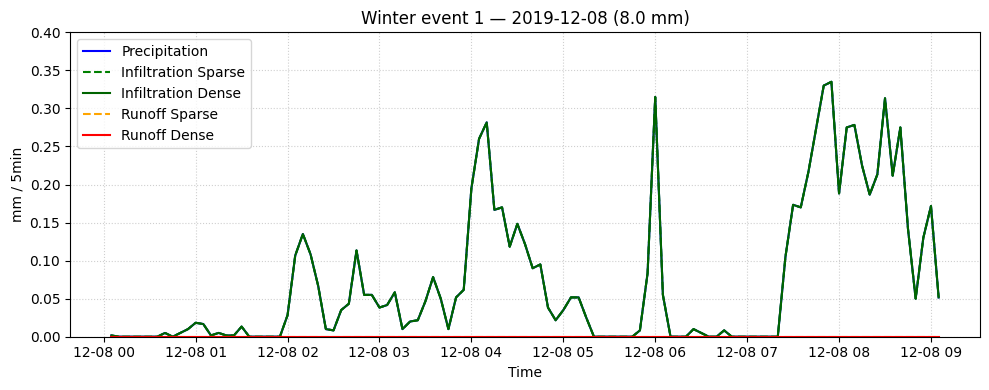

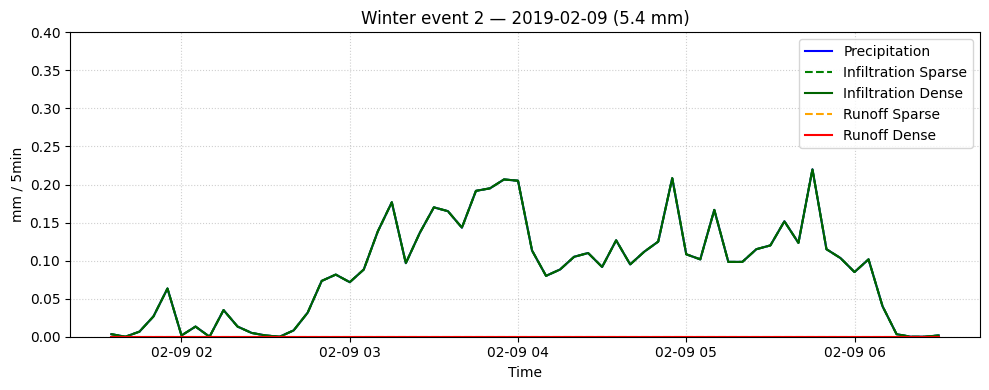

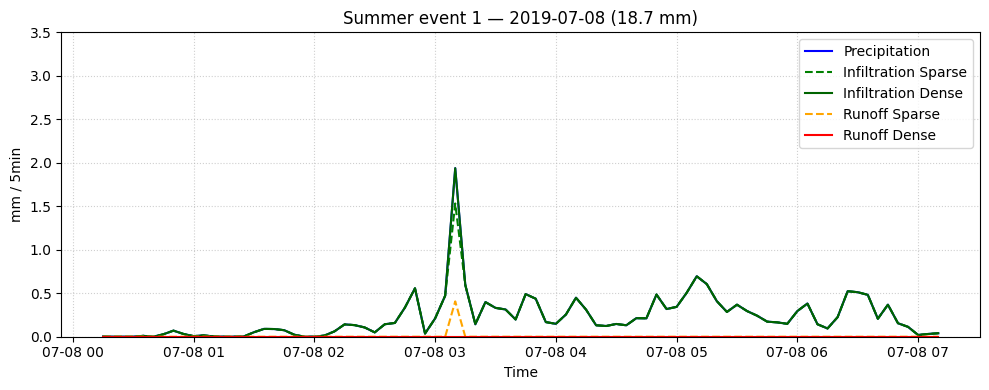

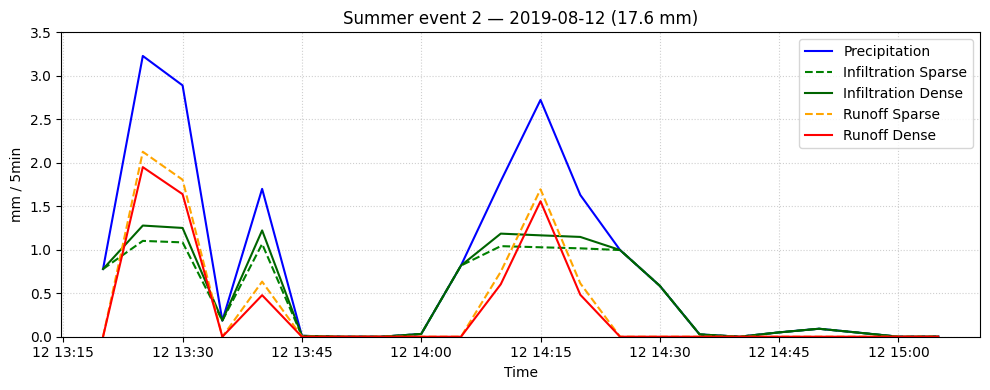

In [29]:
events = [winter_events, summer_events]

precip_5min = met_data['rain_intensity'].resample('5Min').ffill() * dt/60

for event_df in events:

    if event_df is winter_events:
        season = 'Winter'
        ylim = 0.4
    else:
        season = 'Summer'
        ylim = 3.5

    for i, row in event_df.head(2).iterrows():

        event_precip   = precip_5min.loc[row['start']:row['end']]
        event_I_sparse = I_5min_sparse.loc[row['start']:row['end']]
        event_I_dense  = I_5min_dense.loc[row['start']:row['end']]
        event_RO_sparse = event_precip - event_I_sparse
        event_RO_dense  = event_precip - event_I_dense

        fig, ax = plt.subplots(figsize=(10, 4))
        ax.plot(event_precip.index,   event_precip.values,    label='Precipitation',      color='blue')
        ax.plot(event_I_sparse.index, event_I_sparse.values,  label='Infiltration Sparse', color='green',  linestyle='--')
        ax.plot(event_I_dense.index,  event_I_dense.values,   label='Infiltration Dense',  color='darkgreen')
        ax.plot(event_RO_sparse.index,event_RO_sparse.values, label='Runoff Sparse',       color='orange', linestyle='--')
        ax.plot(event_RO_dense.index, event_RO_dense.values,  label='Runoff Dense',        color='red')
        ax.set_title(f'{season} event {i+1} — {row["start"].date()} ({row["total_mm"]:.1f} mm)')
        ax.set_ylim(0, ylim)
        ax.set_xlabel('Time')
        ax.set_ylabel('mm / 5min')
        ax.legend()
        ax.grid(True, linestyle=':', alpha=0.6)
        plt.tight_layout()
        plt.show()

## Step 5

### Q12) compute a runoff time series for sparse and dense vegetation for all 4 events


We've implemented a runoff time series for both vegetation areas, for the 4 rain events, with the flow of the runoff as $$ Q = A(P-I-ET) $$. What we see in the graphs, is that the events happening during winter, results in no runoff. The summer events, being larger rain events, shows runoff. On summer rain event 1, we see that the sparse area has a short period, where runoff occurs, while no runoff happens at the densely vegetated area. Rain event 2 shows a shorter rain, but with increased intensity. Here both vegetation areas experience runoff.

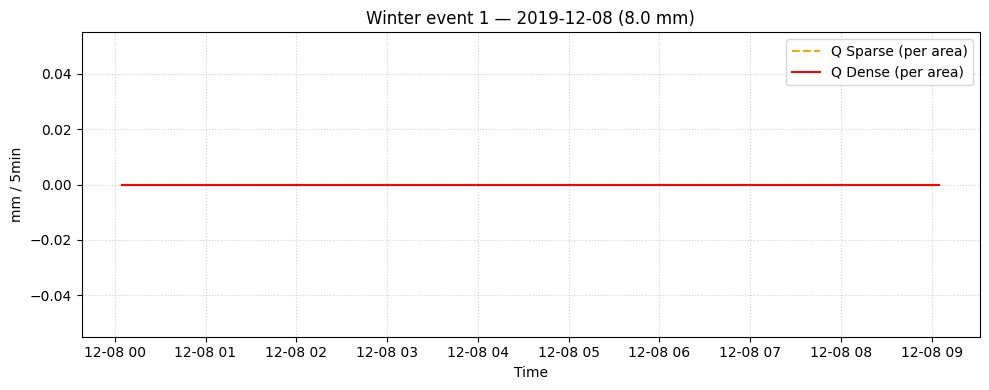

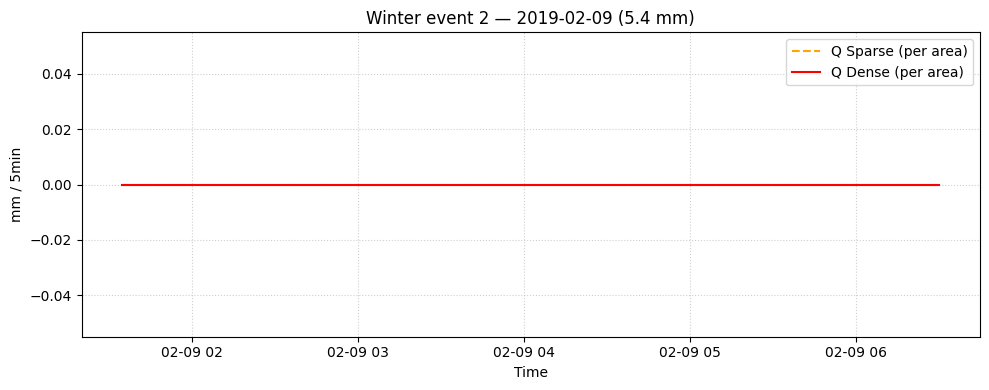

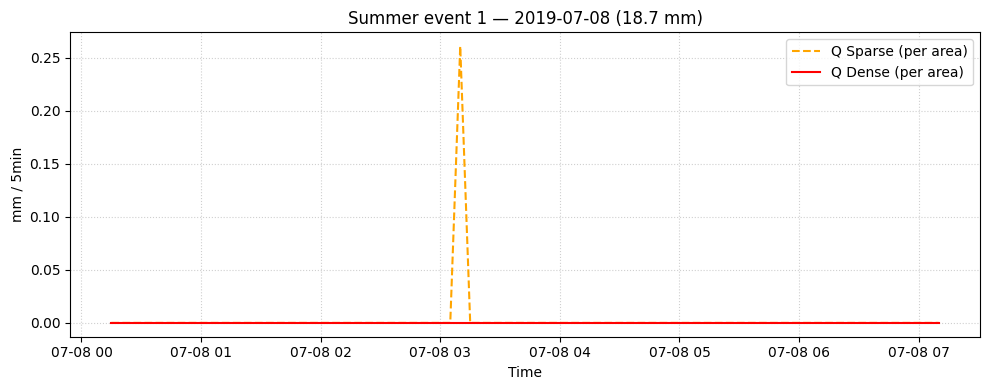

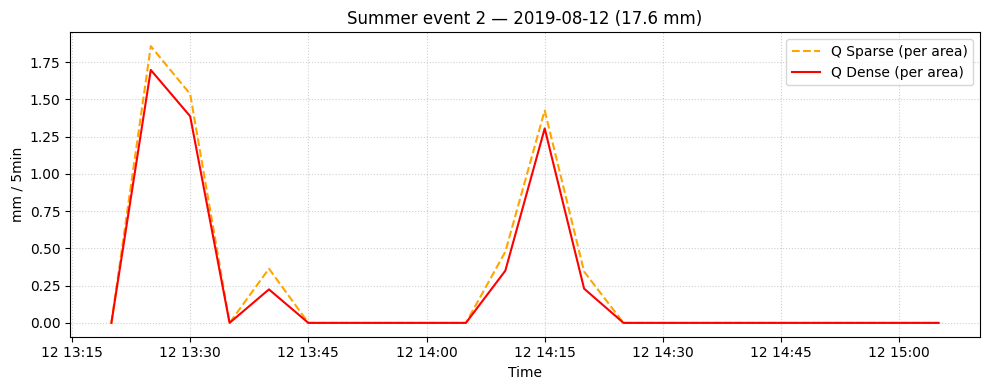

In [30]:
for event_df in events:

    if event_df is winter_events:
        season = 'Winter'
    else:
        season = 'Summer'

    for i, row in event_df.head(2).iterrows():

        common_index = precip_5min.index

        event_precip   = precip_5min.loc[row['start']:row['end']]
        event_I_sparse = I_5min_sparse.loc[row['start']:row['end']].clip(upper=event_precip)
        event_I_dense  = I_5min_dense.loc[row['start']:row['end']].clip(upper=event_precip)

        ET_act_5min_sparse = df_sparse_2019['ET_act'].resample('5Min').ffill().reindex(common_index, method='ffill') * dt/60
        ET_act_5min_dense  = df_dense_2019['ET_act'].resample('5Min').ffill().reindex(common_index, method='ffill') * dt/60

        event_ET_sparse = ET_act_5min_sparse.loc[row['start']:row['end']]
        event_ET_dense  = ET_act_5min_dense.loc[row['start']:row['end']]

        Q_sparse = (((event_precip - event_I_sparse - event_ET_sparse))).clip(lower=0) # conver to mm/5min
        Q_dense = (((event_precip - event_I_dense - event_ET_dense))).clip(lower=0) # convert to mm/5min

        fig, ax = plt.subplots(figsize=(10, 4))
        ax.plot(Q_sparse.index,   Q_sparse.values,    label=f'Q Sparse (per area)',      color='orange', linestyle='--')
        ax.plot(Q_dense.index,   Q_dense.values,    label=f'Q Dense (per area)',      color='Red')
        ax.set_title(f'{season} event {i+1} — {row["start"].date()} ({row["total_mm"]:.1f} mm)')
        ax.set_xlabel('Time')
        ax.set_ylabel('mm / 5min')
        ax.legend()
        ax.grid(True, linestyle=':', alpha=0.6)
        plt.tight_layout()
        plt.show()

### Q13)  Derive a runoff time series for impervious areas

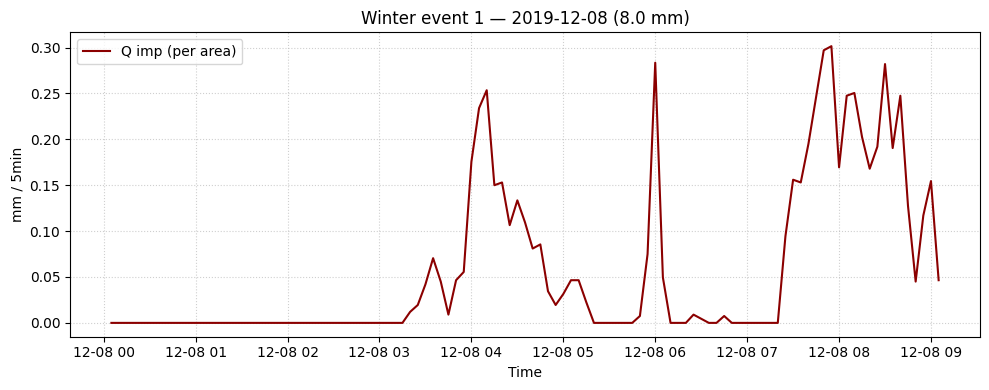

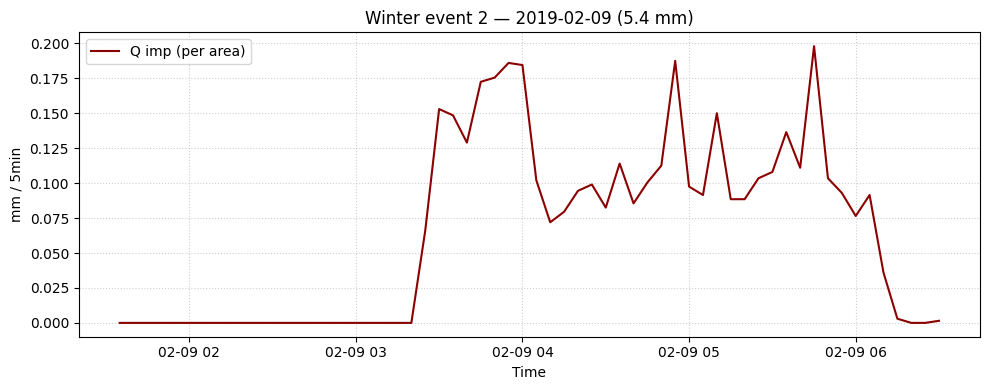

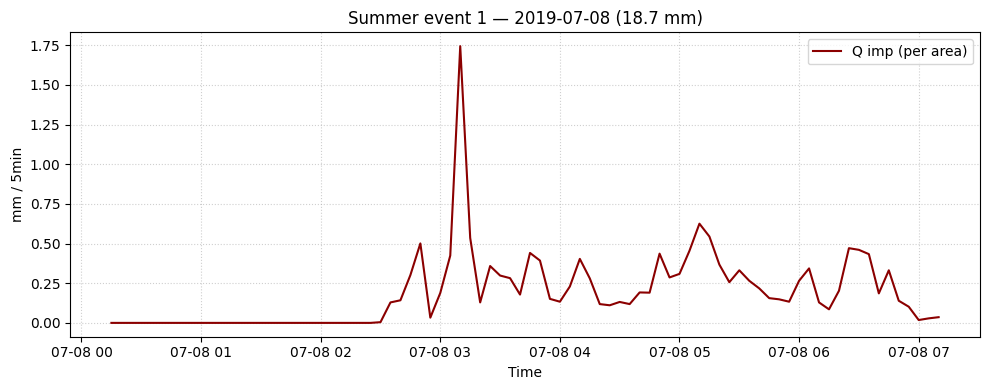

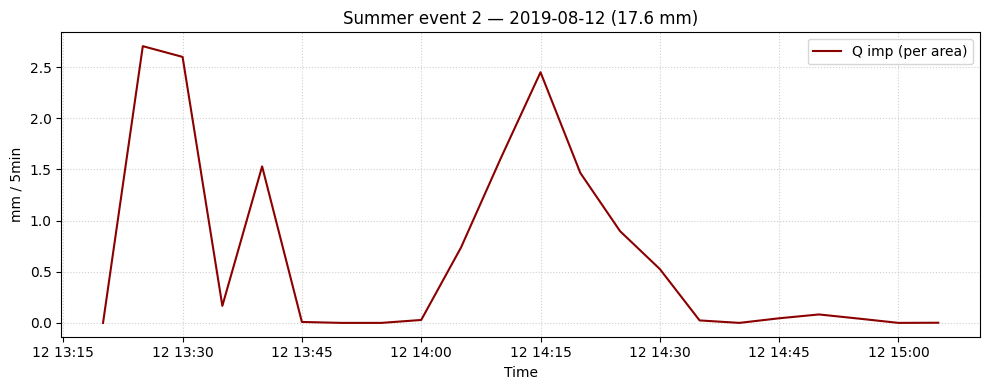

In [31]:
for event_df in events:

    if event_df is winter_events:
        season = 'Winter'
    else:
        season = 'Summer'

    for i, row in event_df.head(2).iterrows():

        event_precip = precip_5min.loc[row['start']:row['end']]

        cumulative = event_precip.cumsum()

        # Subtract 1mm from cumulative — first 1mm wets the surface
        excess = (cumulative - 1.0).clip(lower=0)

        event_precip_imp = excess.diff().clip(lower=0)
        event_precip_imp.iloc[0] = excess.iloc[0]  # first timestep

        # Runoff at each timestep = change in excess * 90%
        Q_imp = np.maximum(event_precip_imp * 0.9, 0)

        fig, ax = plt.subplots(figsize=(10, 4))
        ax.plot(Q_imp.index,   Q_imp.values,    label=f'Q imp (per area)',      color='Darkred', linestyle='-')
        ax.set_title(f'{season} event {i+1} — {row["start"].date()} ({row["total_mm"]:.1f} mm)')
        ax.set_xlabel('Time')
        ax.set_ylabel('mm / 5min')
        ax.legend()
        ax.grid(True, linestyle=':', alpha=0.6)
        plt.tight_layout()
        plt.show()

In Q12, we saw that no runoff occoured in the winter events. On the impervious areas, we see that runoff occour in all events. This is due to all events being the highest in each of their season, resulting in all events having a higher cumulative precipitation, than 1 mm. As a result, all events have additional precipitation above what is required to just wetten the area. We still se similar runoff tendencies for summer event 2, as with the dense and sparse areas.

### Q14) Determine what percentage of the catchment is covered by, respectively, impervious areas, sparse and dense vegetation

In [32]:
vegetation_type = {'Impervious area' :[ 'Paved road','Other paved','Bare rock','Building'],
                   'Sparse vegetation' :['Shallow vegetation','Bare land', 'Unpaved road'],
                   'Dense vegetation':['Dense vegetation']}

# Mapping each land cover category to its vegetation type
mapping = {}
for veg, classes in vegetation_type.items():
    for cls in classes:
        mapping[cls] = veg

# agrregating the mapped land cover categories in sums for vegetation type, for each catchment area as well as total area
df_vegetation = (
    df_landtype
    .set_index('Land Cover Type')
    .rename(index=mapping)
    .groupby(level=0)
    .sum()
    .reset_index()
)

# define dataframe of the total area in cathcment area 
totals = df_landtype[df_landtype['Land Cover Type'] == 'Total area in catchment']

# add percentage columns to the vegetation dataframe
for col in df_vegetation.columns[1:]:
    total = totals[col].values[0]  
    pct_col = col.replace('(ha)', '(%)')
    df_vegetation[pct_col] = df_vegetation[col] / total * 100

df_vegetation.round(2)

,Land Cover Type,catchment00 (ha),catchment01 (ha),catchment02 (ha),Total (ha),catchment00 (%),catchment01 (%),catchment02 (%),Total (%)
0,Dense vegetation,24.84,7.19,2.48,34.51,28.38,28.51,21.69,27.79
1,Impervious area,49.25,13.89,7.19,70.33,56.27,55.08,62.90,56.64
2,Sparse vegetation,13.43,4.14,1.76,19.32,15.34,16.40,15.41,15.56
3,Total area in catchment,87.51,25.21,11.44,124.16,100.00,100.00,100.00,100.00


### Q 15) Determine which area types contribute most to the total runoff during the considered rain events.

The area of the catchments are distributed as so: 
- 15.34 % is sparse vegetation,
- 28.38 % is dense vegetation, and
- 56.27 % is impervious area. 

The impervious area contributes most to the total runoff from the catchment due to its large coverage (56.27%) and very low infiltration capacity. In these areas, most precipitation is converted directly into surface runoff because infiltration is negligible.

Vegetated areas, including both sparse and dense vegetation, have higher infiltration capacities and therefore generate less runoff compared to impervious surfaces. However, during high-intensity rainfall events, the soil can become saturated, leading to increased runoff even from vegetated areas.

Overall, runoff from vegetated areas is expected to be significantly lower than from impervious areas, both due to their smaller spatial extent and higher infiltration rates.

In [33]:
A_sparse = float(df_landtype.loc[
    df_landtype['Land Cover Type'].isin(['Shallow vegetation', 'Bare land', 'Unpaved road']),
    'catchment00 (ha)'].sum()) * 1e4

A_dense = float(df_landtype.loc[
    df_landtype['Land Cover Type'] == 'Dense vegetation',
    'catchment00 (ha)'].values[0]) * 1e4

A_imp = float(df_landtype.loc[
    ~df_landtype['Land Cover Type'].isin(['Shallow vegetation', 'Dense vegetation',
                                          'Bare land', 'Unpaved road',
                                          'Total area in catchment']),
    'catchment00 (ha)'].sum()) * 1e4


results = []
Q_results = {}


for event_df, season in [(winter_events, 'Winter'), (summer_events, 'Summer')]:
    for i, row in event_df.head(2).iterrows():

        common_index = precip_5min.index
        event_precip = precip_5min.loc[row['start']:row['end']]

        # Sparse and dense
        event_I_sparse = I_5min_sparse.loc[row['start']:row['end']].clip(upper=event_precip)
        event_I_dense  = I_5min_dense.loc[row['start']:row['end']].clip(upper=event_precip)

        ET_act_5min_sparse = df_sparse_2019['ET_act'].resample('5Min').ffill().reindex(common_index, method='ffill') * dt/60
        ET_act_5min_dense  = df_dense_2019['ET_act'].resample('5Min').ffill().reindex(common_index, method='ffill') * dt/60

        event_ET_sparse = ET_act_5min_sparse.loc[row['start']:row['end']]
        event_ET_dense  = ET_act_5min_dense.loc[row['start']:row['end']]

        Q_sparse = ((event_precip - event_I_sparse - event_ET_sparse) / (dt * 60)).clip(lower=0)
        Q_dense  = ((event_precip - event_I_dense  - event_ET_dense)  / (dt * 60)).clip(lower=0)

        # Impervious
        cumulative = event_precip.cumsum()
        excess     = (cumulative - 1.0).clip(lower=0)
        event_precip_imp = excess.diff().clip(lower=0)
        event_precip_imp.iloc[0] = excess.iloc[0]
        Q_imp = (event_precip_imp * 0.9) / (dt * 60)

        # Total volume m³ = mm/s × dt×60 s × m² / 1000
        V_sparse = Q_sparse.sum() * (dt * 60) * A_sparse / 1000
        V_dense  = Q_dense.sum()  * (dt * 60) * A_dense  / 1000
        V_imp    = Q_imp.sum()    * (dt * 60) * A_imp    / 1000
        V_total  = V_sparse + V_dense + V_imp

        results.append({
            'Season':                season,
            'Event':                 i + 1,
            'Q_sparse (m³)':         float(V_sparse),
            'Q_dense (m³)':          float(V_dense),
            'Q_imp (m³)':            float(V_imp),
            'Q_total (m³)':          float(V_total),
            'Q_sparse (% of total)': float(V_sparse / V_total * 100),
            'Q_dense (% of total)':  float(V_dense  / V_total * 100),
            'Q_imp (% of total)':    float(V_imp    / V_total * 100),
        })  # closing }) must be at same indent level as opening results.append(

        Q_results[(season, i+1)] = {
            'Q_sparse': Q_sparse * A_sparse / 1000,  # m³/s
            'Q_dense':  Q_dense  * A_dense  / 1000,
            'Q_imp':    Q_imp    * A_imp    / 1000,
            'date':     row['start'].date(),
            'total_mm': row['total_mm'],
        }



df_results = pd.DataFrame(results).set_index(['Season', 'Event'])

display(df_results.style.format({
    'Q_sparse (m³)':         '{:.2f}',
    'Q_dense (m³)':          '{:.2f}',
    'Q_imp (m³)':            '{:.2f}',
    'Q_total (m³)':          '{:.2f}',
    'Q_sparse (% of total)': '{:.1f}%',
    'Q_dense (% of total)':  '{:.1f}%',
    'Q_imp (% of total)':    '{:.1f}%',
}))


We see that even though summer rain event 1 (18.7 mm) has more cumulative precipitation than summer rain event 2 (17.6), that summer rain event 2 resulted in a higher total runoff. This is due to rain event 2 being a more intense rain event, during a shorter period of time. In the table above, it's possible to see that $Q_{imp}$ is a bit lower, while both vegetation areas supply a substantial runoff (8.5% and 13.7% of the events total runoff). 

What this tells us is that the more impervious area over a catchment, the more mobile the rain becomes as runoff. This in turn shows, that hydrological solutions are required, when dealing with problems in cities, or other highly impervious areas.

During the winter, the largest rain events have happened over an extended period of time, where the rain was able to infiltrate the sparse and dense areas. All the largest rain events had a precipitation above 1 mm, but a majority of rain events did not.

### Q16) 
We apply the empirical formula: Kirpich, for the time of concentration, $T_c$ determination. We use this formula, because the green area (catchment00) has a size of 87 ha $\approx$ 0.87 $km^2$ which is less than 2 $km^2$.  Furhtermore the formula asusmes a rual watershed, which is in allignment with the assumption of a natural catchment behaviour. 

$$
T_c = 0.0195 \cdot L^{0.77} \cdot S^{-0.385}
$$

In [34]:
mask = catchment00 != 0

terrain_masked = np.where(mask, terrain, np.nan)

# Lowest point in catchment
min_row, min_col = np.unravel_index(np.nanargmin(terrain_masked), terrain_masked.shape)

min_x = transform.c + min_col * transform.a
min_y = transform.f + min_row * transform.e

# define all pixel coordinates in catchment
rows, cols = np.where(mask)

xs = transform.c + cols * transform.a
ys = transform.f + rows * transform.e

# Compute distances from lowest point to all pixels in catchment
distances = np.sqrt((xs - min_x)**2 + (ys - min_y)**2)

# Futherest point from lowest point
max_idx = np.argmax(distances)

max_x = xs[max_idx]
max_y = ys[max_idx]
L = distances[max_idx] # m

S = (0.05+0.1)/2 # m/m

Tc = 0.0195*L**(0.77)*S**(-0.385) #time of concentration (min)
Tc

np.float64(11.736225817943897)

### Q17)

The catchment is assummed to act a a single linear reservoir.

For simpllification it is also assumed the the time of concentration $T_c$ directly corresponds to the reservoir constant $K$. 

We may therefore define the reservoir constant as:

$$ K = T_c \cdot 60 $$

For a single linear reservoir the follwing eqations are utulized:

Continuity:

$$ \frac{dSto(t)}{dt} = Q_{in}(t) - Q_{out}(t) $$

where

$$ Q_{in} = Q_{in, dense} + Q_{in, sparse} + Q_{in, imp} $$

Storage:

$$ Sto(t) = K \cdot Q_{out}(t) \rightarrow Q_{out}(t) = \frac{Sto(t)}{K} $$

where

$$ \frac{dSto(t)_i}{dt_i} = Q_{in, i} - Q_{out, i-1} $$

and

$$ Sto(t) = max(Sto(t)_{i-1} + \frac{dSto(t)_i}{dt_i} \cdot \Delta{t}, \: 0) $$


From the events we see expected behaviour for single linear reservoir of instantaneous sudden spike after percipitation with a lag in storage depletion of the catchment following an the shape of an expected decay equation.

$$Out_i = Out_{i-1}e^{-\frac{\Delta t}{K}}$$

Due to the high resoltuion of 5 minute time steps the event precipitation are more continuous comapred to a lower resolution which would provide a more distinct impulse response to the system. However, for both winter events 1 and 2 and summer event 2 we see the clear decay tail at the end of the rain event.

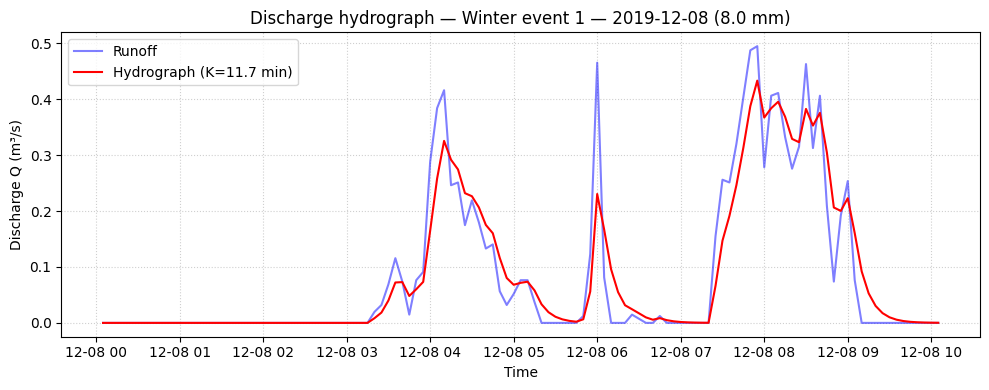

sum discharge (m³) for Winter event 1: 3103.84 m³


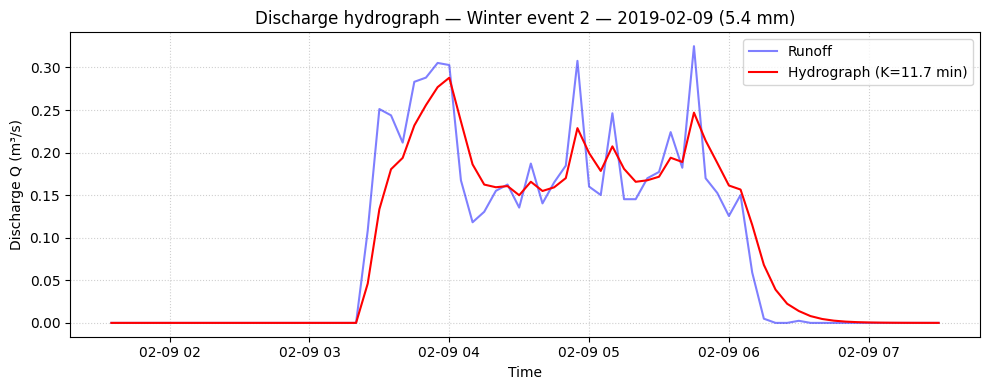

sum discharge (m³) for Winter event 2: 1931.64 m³


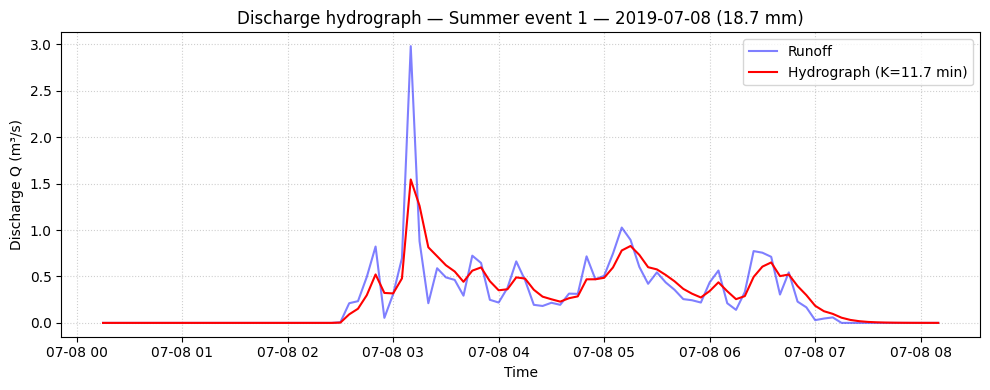

sum discharge (m³) for Summer event 1: 7870.87 m³


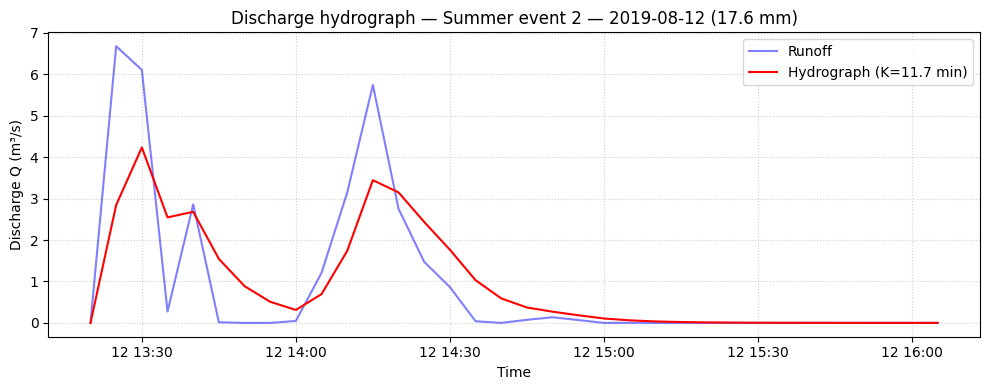

sum discharge (m³) for Summer event 2: 9445.13 m³


In [35]:
K    = Tc * 60
dt_s = dt * 60
n_extra = int(1 * 60 / dt)  # 2 hours of extra timesteps

def linear_reservoir(Q_in, K):
    Q_out = np.zeros(len(Q_in))
    S = 0
    for i in range(1, len(Q_in)):
        S = max(S + (Q_in[i] - Q_out[i-1]) * dt_s, 0)
        Q_out[i] = S / K
    return Q_out

for (season, event), Q in Q_results.items():

    Q_total_series = (Q['Q_sparse'] + Q['Q_dense'] + Q['Q_imp']).fillna(0)

    # Pad with zeros for 2 extra hours
    Q_total_padded = np.append(Q_total_series.values, np.zeros(n_extra))
    extended_index = pd.date_range(
        start=Q_total_series.index[0],
        periods=len(Q_total_padded),
        freq='5Min'
    )

    Q_routed = linear_reservoir(Q_total_padded, K)

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(extended_index, Q_total_padded, label='Runoff', color='blue', alpha=0.5)
    ax.plot(extended_index, Q_routed,       label=f'Hydrograph (K={Tc:.1f} min)',   color='red')
    ax.set_title(f'Discharge hydrograph — {season} event {event} — {Q["date"]} ({Q["total_mm"]:.1f} mm)')
    ax.set_xlabel('Time')
    ax.set_ylabel('Discharge Q (m³/s)')
    ax.legend()
    ax.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

    print(f"sum discharge (m³) for {season} event {event}: {Q_routed.sum() * dt_s:.2f} m³")

## Declaration of AI

This notebook has been developed for assignment 4 in the course 12320 Hydrology F26 at DTU Lyngby.

This assingment has been produced with the use of ChatGPT model 5.5 during April/May of 2026.

The AI has been used to help with data infrastructure setup, syntax errors, plotting and generel coding assistance.

All contents of this notebook have been read, reviewed and edited to ensure it represents the understanding of the students of admission and fulfills assignment requirements.

The students of admission takes full responsibility for the contents of this notebook.